# Agricultural crop yield forecasting — final evaluation edition
**Bennett University · CSET 369**  
Mayank Yadav — S24CSEU1494

This edition preserves the original working experiment’s seven-column input and 2005–2014 matched cohort, expands XGBoost tuning to 12 chronological trials, and adds genuinely trained LSTM, GRU and a tiny patch-based Transformer. Prophet has a separate longer-history aggregate experiment and an explicit failure status if its native optimizer cannot run. AR1_OLS and custom least-squares smoothing are labeled accurately; no ARIMA result is invented.

Use **crop_production.csv** (246,091 rows), not the older 16-column input. Scores are calculated, not prefilled. The raw file includes partial 2015 reporting, while the modeled cutoff is 2014. Forecasts cover 2015–2017 and are not observations.

**Scientific limits:** retrospective balanced-cohort selection; seven pre-test annual observations; only two outer validation years and three test years; units, source/license and district boundaries unverified. The test period was examined in the previous study, so this extension is not an independent prospective holdout. The official milestone PDFs were not available for exact certification.

## 1 Free CPU environment and dependency check
Colab normally supplies PyTorch. Missing PyTorch uses the official CPU wheel index. The local audit records exact installed versions; Colab resource availability and versions can differ. No paid runtime or service is requested.

In [1]:
import os,sys,subprocess,importlib.util,importlib.metadata as package_metadata
from pathlib import Path
COLAB_MODE=bool(importlib.util.find_spec('google.colab')) if importlib.util.find_spec('google') else False
if COLAB_MODE:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','numpy>=1.26','pandas>=2.2','scipy>=1.13','statsmodels>=0.14','scikit-learn>=1.5','xgboost>=2.1','matplotlib>=3.9','prophet>=1.1'])
    try:
        current_torch=tuple(int(x) for x in package_metadata.version('torch').split('+')[0].split('.')[:2])
    except package_metadata.PackageNotFoundError:
        current_torch=(0,0)
    if current_torch<(2,4):
        subprocess.check_call([sys.executable,'-m','pip','install','-q','torch>=2.4','--index-url','https://download.pytorch.org/whl/cpu'])
print('CPU-only experiment; no paid services. Colab mode:',COLAB_MODE)


CPU-only experiment; no paid services. Colab mode: False


## 2 Upload and validate the confirmed dataset
Only the returned CSV payload is accepted; the original source file is preserved. A different CSV with the same schema can change every result and requires a new report.

In [2]:
EXPECTED_COLUMNS={'State_Name','District_Name','Crop_Year','Season','Crop','Area','Production'}
def configure_dataset(csv_path=None,upload_callback=None):
    if upload_callback is not None:
        uploaded=upload_callback()
        names=[name for name in uploaded if name.lower().endswith('.csv')]
        if len(names)!=1:raise ValueError('Upload exactly one crop_production.csv file.')
        path=Path(names[0]).name
        Path(path).write_bytes(uploaded[names[0]])
    else:
        path=str(csv_path or os.environ.get('APY_CSV','crop_production.csv'))
    if not Path(path).is_file():raise FileNotFoundError('Set APY_CSV or upload crop_production.csv.')
    import csv
    with Path(path).open(encoding='utf-8-sig',newline='') as handle:header=next(csv.reader(handle))
    if set(header)!=EXPECTED_COLUMNS:raise ValueError(f'Expected seven-column crop_production.csv; received {header}')
    os.environ['APY_CSV']=str(Path(path).resolve())
    return Path(path)
if COLAB_MODE:
    from google.colab import files
    data_path=configure_dataset(upload_callback=files.upload)
    os.environ['APY_OUTPUT']='/content/crop_yield_final_results'
else:
    data_path=configure_dataset()
    os.environ.setdefault('APY_OUTPUT','results')
print('Dataset:',data_path.name)


Dataset: crop_production.csv


## 3 Data quality and conservative annual panel

In [3]:
from pathlib import Path
import os
import time,json,hashlib,warnings,platform,importlib.metadata as meta
import numpy as np,pandas as pd
import matplotlib;matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox,het_arch
from xgboost import XGBRegressor
ROOT=Path(os.environ.get('APY_OUTPUT','results'));ROOT.mkdir(exist_ok=True);FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
np.random.seed(42); T0=time.perf_counter()
def js(name,o):(ROOT/name).write_text(json.dumps(o,indent=2,default=str),encoding='utf-8')
def save(name):
 plt.tight_layout(); path=FIG/(name+'.png'); plt.savefig(path,dpi=300,bbox_inches='tight'); plt.close()
 try:
  from IPython.display import display, Image
  display(Image(filename=str(path)))
 except ImportError:
  print('Saved figure:',path)

plt.rcParams.update({'font.size':8.5,'axes.spines.top':False,'axes.spines.right':False})
raw=pd.read_csv(os.environ.get('APY_CSV','raw/crop_production.csv'));d=raw.copy()
for c in ['State_Name','District_Name','Season','Crop']:d[c]=d[c].str.strip().str.replace(r'\s+',' ',regex=True)
key=['State_Name','District_Name','Crop','Crop_Year'];bk=key+['Season']
num=['Area','Production'];d['valid']=np.isfinite(d.Area)&np.isfinite(d.Production)&d.Area.gt(0)&d.Production.ge(0)
d['duplicate']=d.duplicated(bk,keep=False)
summary={'rows':len(raw),'columns':len(raw.columns),'states':d.State_Name.nunique(),'district_name_labels':d.District_Name.nunique(),'state_district_pairs':d[['State_Name','District_Name']].drop_duplicates().shape[0],'crops_raw':raw.Crop.nunique(),'crops_standardized':d.Crop.nunique(),'start_year':int(d.Crop_Year.min()),'end_year':int(d.Crop_Year.max()),'missing':raw.isna().sum().to_dict(),'exact_duplicates':int(raw.duplicated().sum()),'business_duplicate_rows':int(d.duplicate.sum()),'nonpositive_area':int(d.Area.le(0).sum()),'negative_production':int(d.Production.lt(0).sum()),'season_counts':d.Season.value_counts().to_dict(),'raw_rows_by_year':d.Crop_Year.value_counts().sort_index().to_dict(),'units':'not encoded; production/area ratio reported without asserting verified tonnes/hectare'}
js('dataset_summary.json',summary); print('RAW',summary,flush=True)
rows=[];aud=[]
for k,g in d.groupby(key):
 reason='included'
 if g.duplicate.any():reason='duplicate_business_key'
 elif g.Season.eq('Whole Year').any() and len(g)>1:reason='whole_year_overlap'
 elif not g.valid.all():reason='invalid_or_missing_component'
 aud.append(dict(zip(key,k),decision=reason,n_raw=len(g)))
 if reason=='included':
  a=g.Area.sum();p=g.Production.sum();rows.append(dict(zip(key,k),area=a,production=p,y=p/a))
panel=pd.DataFrame(rows).sort_values(key);panel['sid']=panel.State_Name+'|'+panel.District_Name+'|'+panel.Crop
panel.to_csv(ROOT/'annual_panel.csv',index=False);audit=pd.DataFrame(aud);audit.to_csv(ROOT/'aggregation_audit.csv',index=False)
quality={'annual_panel_rows':len(panel),'annual_groups_by_decision':audit.decision.value_counts().to_dict(),'raw_rows_by_decision':audit.groupby('decision').n_raw.sum().to_dict(),'no_production_imputation':True,'outliers_removed':0}
js('preprocessing_summary.json',quality)
cov=panel.groupby('sid').Crop_Year.agg(['min','max','count']);cov['missing_internal_years']=cov['max']-cov['min']+1-cov['count'];cov.to_csv(ROOT/'continuity_report.csv')
CROPS=['Rice','Maize','Wheat','Rapeseed &Mustard']
subset=panel[panel.Crop.isin(CROPS)]
w=subset.pivot(index='sid',columns='Crop_Year',values='y').reindex(columns=list(range(2005,2015)))
wide=w.dropna(); ids=wide.index
metadata=panel[['sid','State_Name','District_Name','Crop']].drop_duplicates('sid').set_index('sid').loc[ids]
metadata.to_csv(ROOT/'selected_series.csv');wide.to_csv(ROOT/'model_panel.csv')
assert len(wide)>0
print('SELECTED',wide.shape,metadata.Crop.value_counts().to_dict(),flush=True)
js('experimental_design.json',{'crops':CROPS,'n_series':len(wide),'n_panel_observations':int(wide.size),'excluded_incomplete_series':len(w)-len(wide),'train_final':[2005,2011],'validation_targets':[2010,2011],'validation_origins':[2009,2010],'one_step_test_targets':[2012,2013,2014],'fixed_origin_test':{'origin':2011,'targets':[2012,2013,2014]},'raw_2015_excluded':'562 records; incomplete coverage relative to other years','modeled_cutoff':2014,'future_targets':[2015,2016,2017],'survivor_bias':'eligibility requires complete test-era observations','seed':42,'series_selection':'four named crops matching earlier experiment scope','units':'production units / area units; physical labels absent'})




RAW {'rows': 246091, 'columns': 7, 'states': 33, 'district_name_labels': 646, 'state_district_pairs': 652, 'crops_raw': 124, 'crops_standardized': 124, 'start_year': 1997, 'end_year': 2015, 'missing': {'State_Name': 0, 'District_Name': 0, 'Crop_Year': 0, 'Season': 0, 'Crop': 0, 'Area': 0, 'Production': 3730}, 'exact_duplicates': 0, 'business_duplicate_rows': 0, 'nonpositive_area': 0, 'negative_production': 0, 'season_counts': {'Kharif': 95951, 'Rabi': 66987, 'Whole Year': 57305, 'Summer': 14841, 'Winter': 6058, 'Autumn': 4949}, 'raw_rows_by_year': {1997: 8899, 1998: 11533, 1999: 12515, 2000: 13658, 2001: 13361, 2002: 16671, 2003: 17287, 2004: 14117, 2005: 13799, 2006: 14328, 2007: 14526, 2008: 14550, 2009: 14116, 2010: 14065, 2011: 14071, 2012: 13410, 2013: 13650, 2014: 10973, 2015: 562}, 'units': 'not encoded; production/area ratio reported without asserting verified tonnes/hectare'}


SELECTED (1112, 10) {'Rice': 319, 'Maize': 278, 'Wheat': 267, 'Rapeseed &Mustard': 248}


## 4 Time series EDA

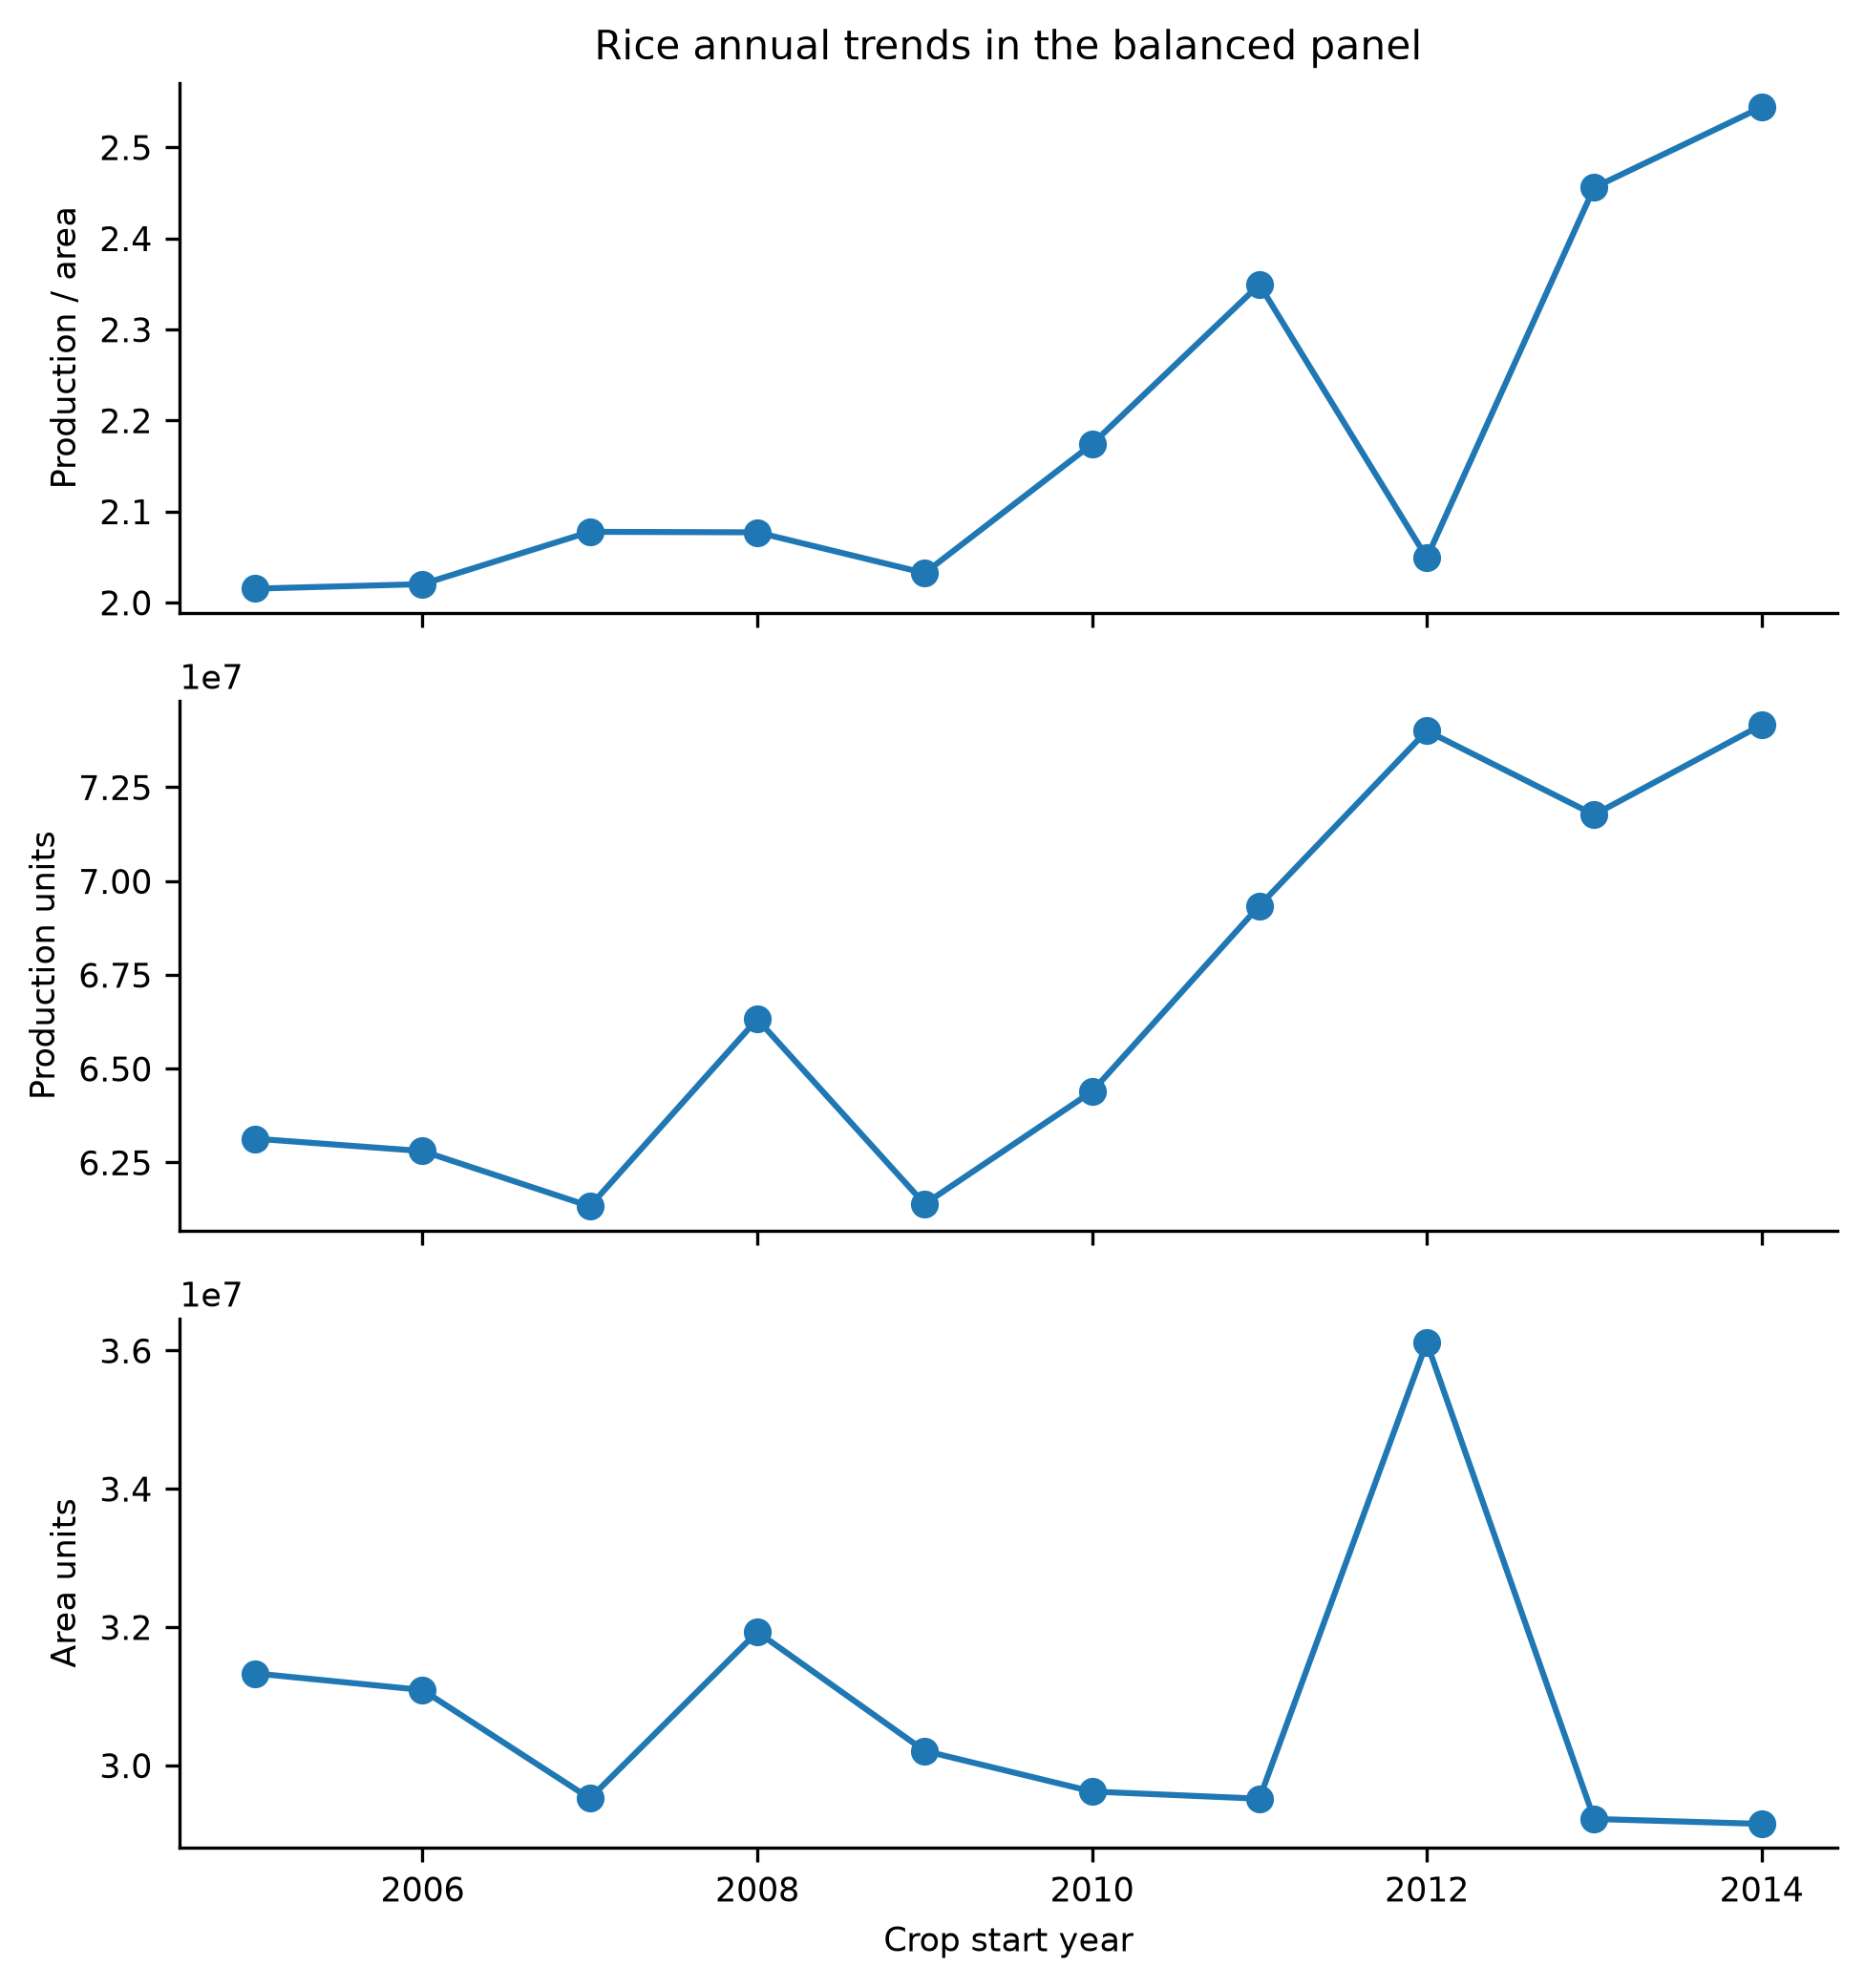

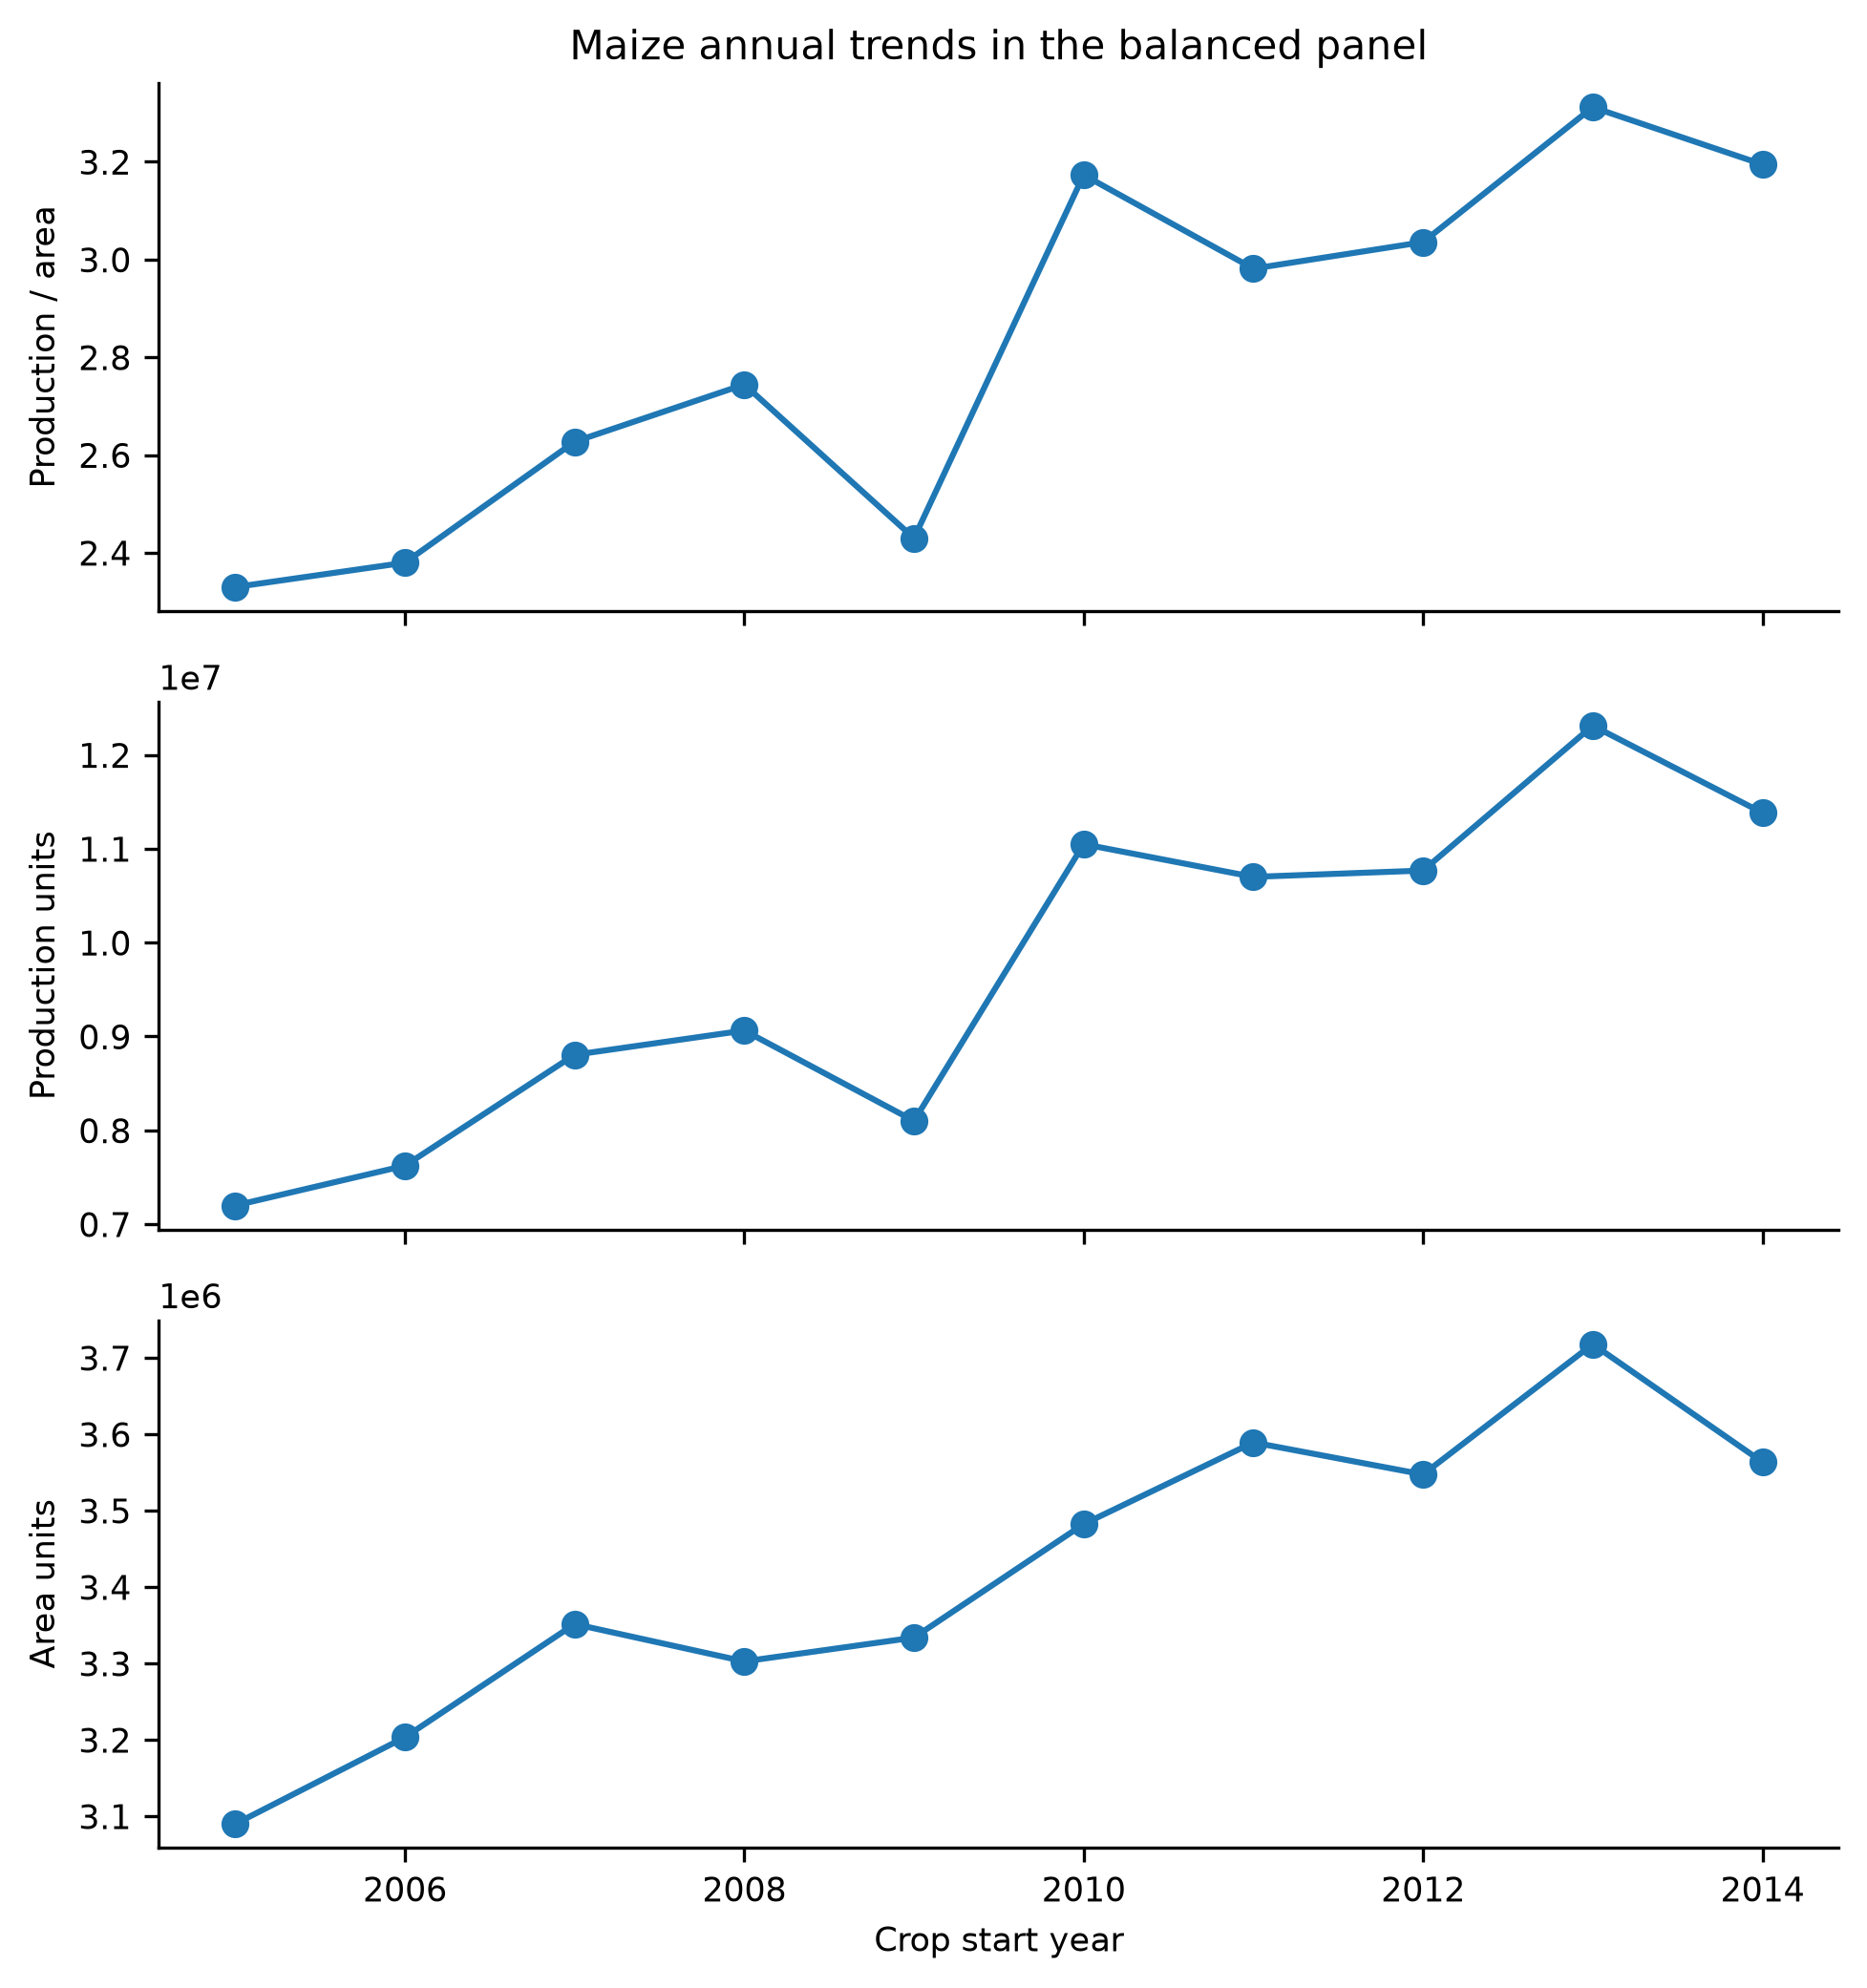

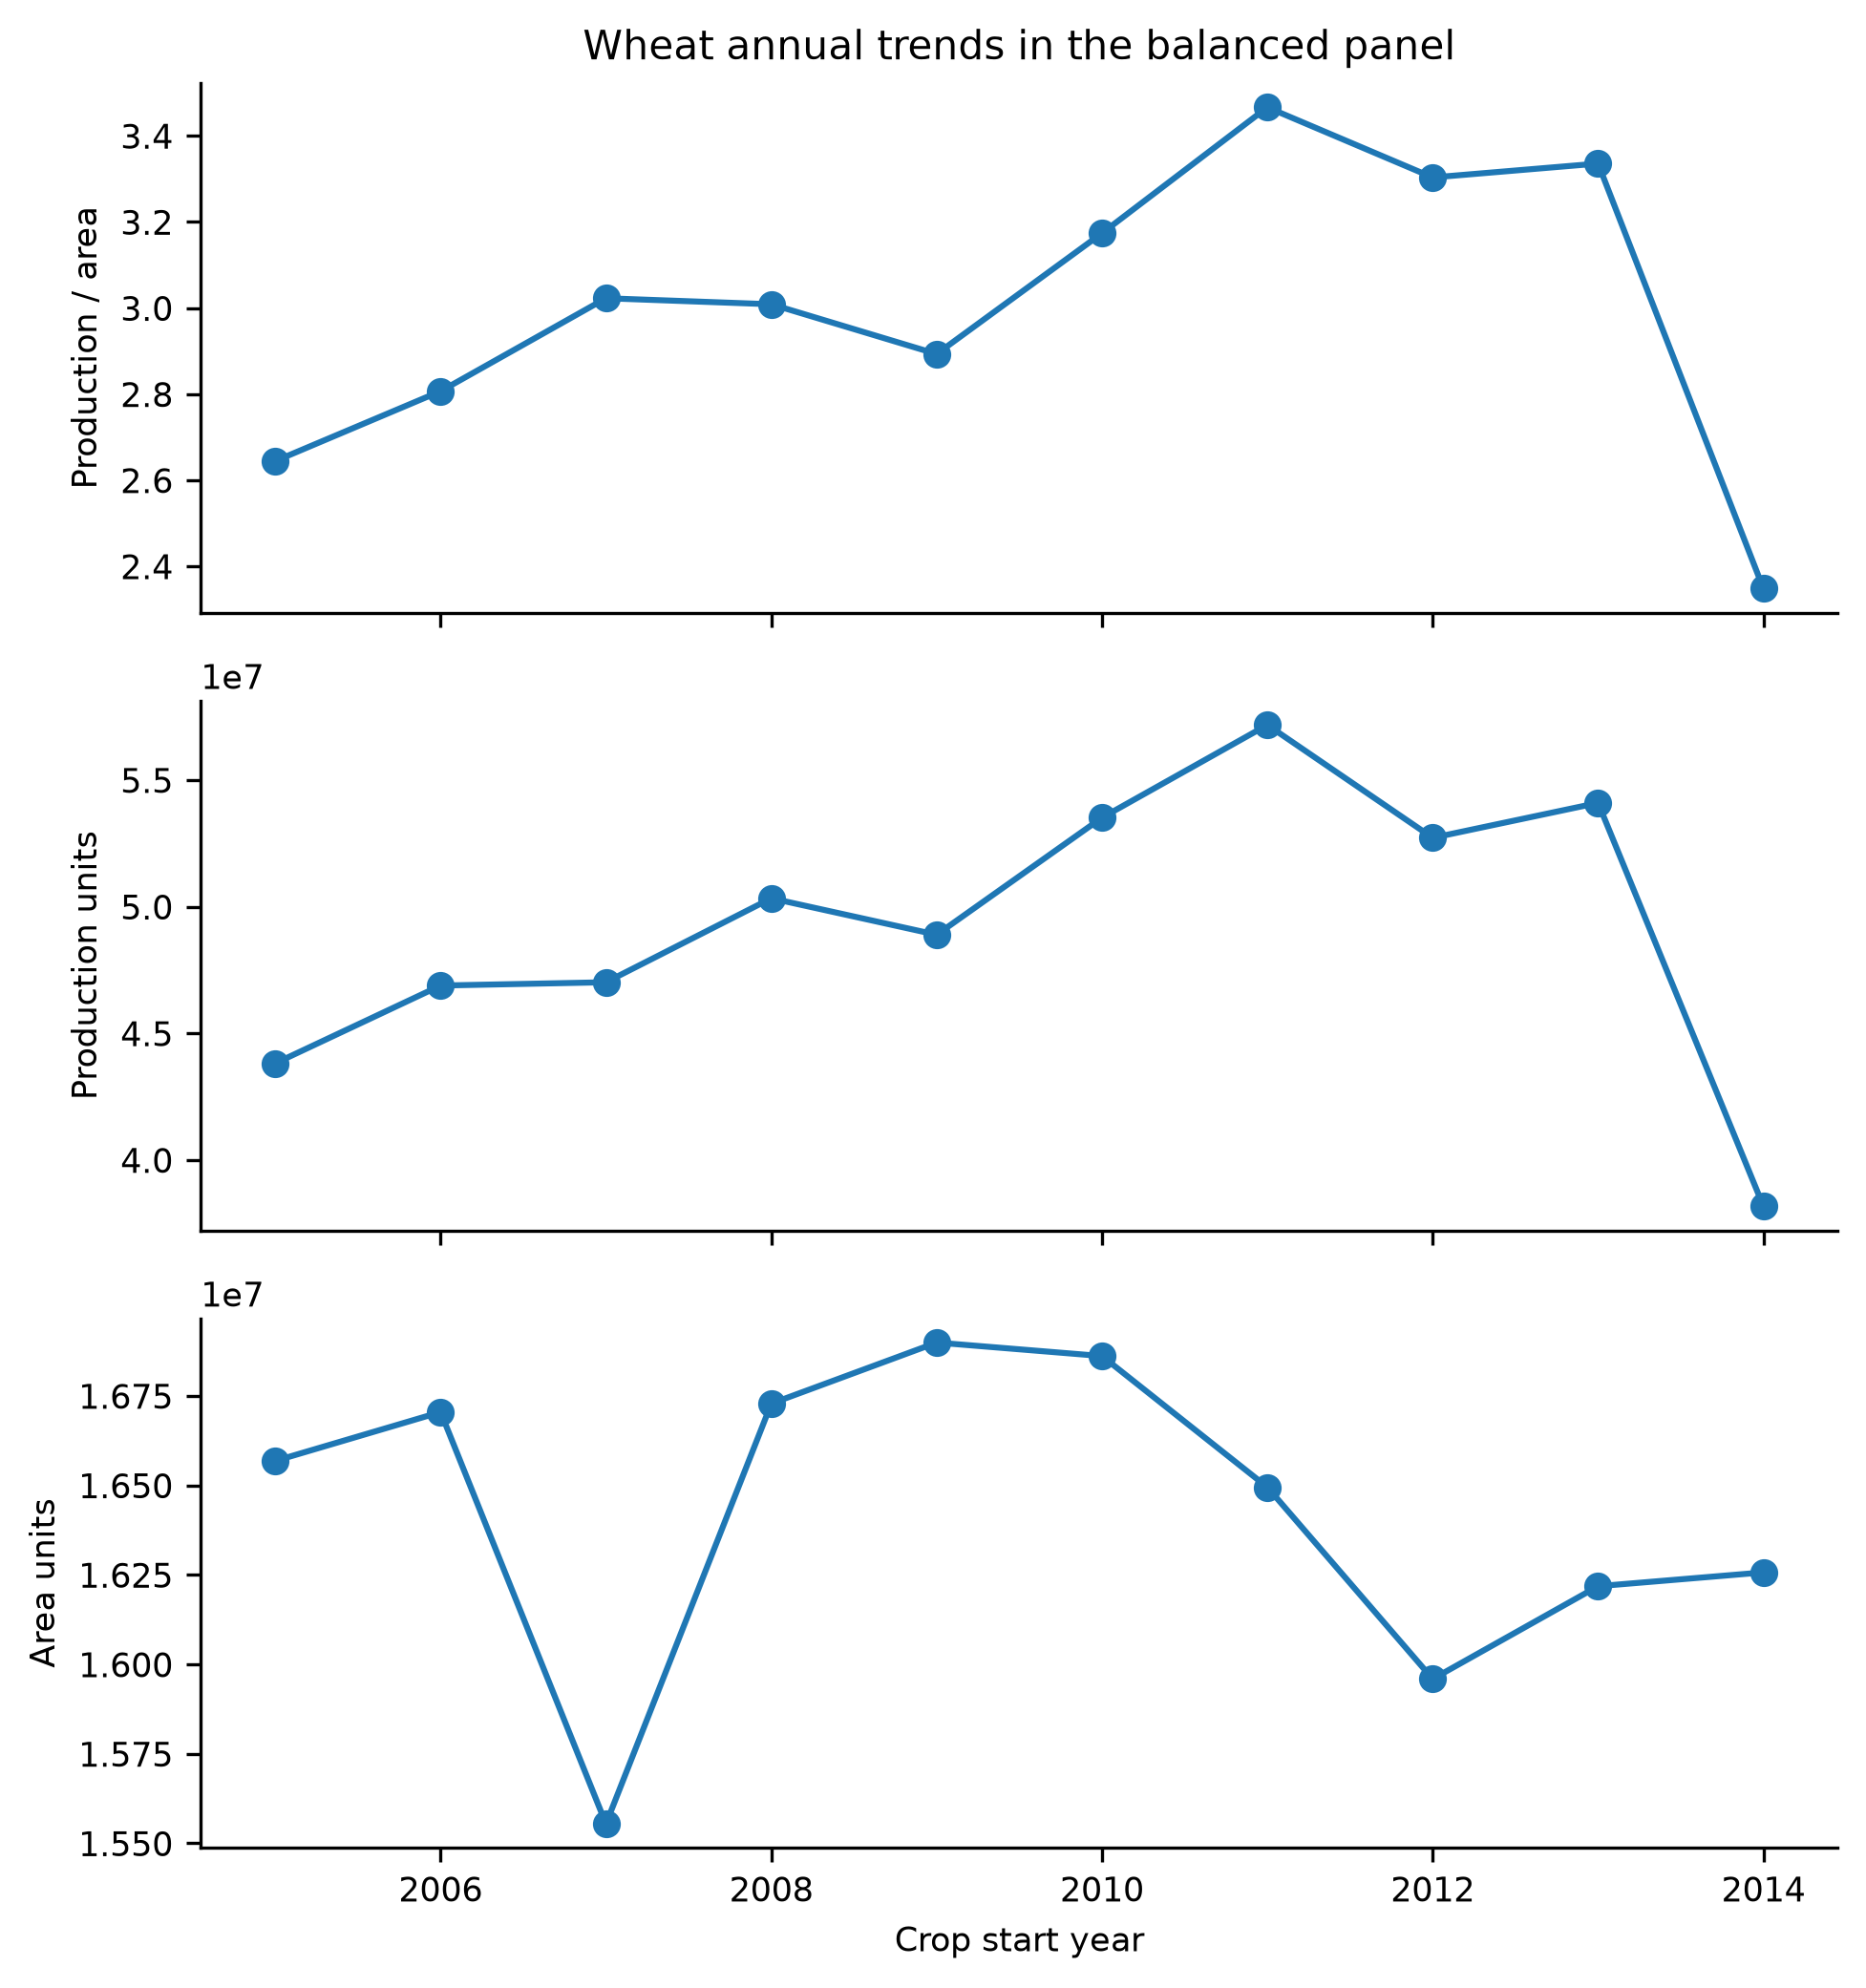

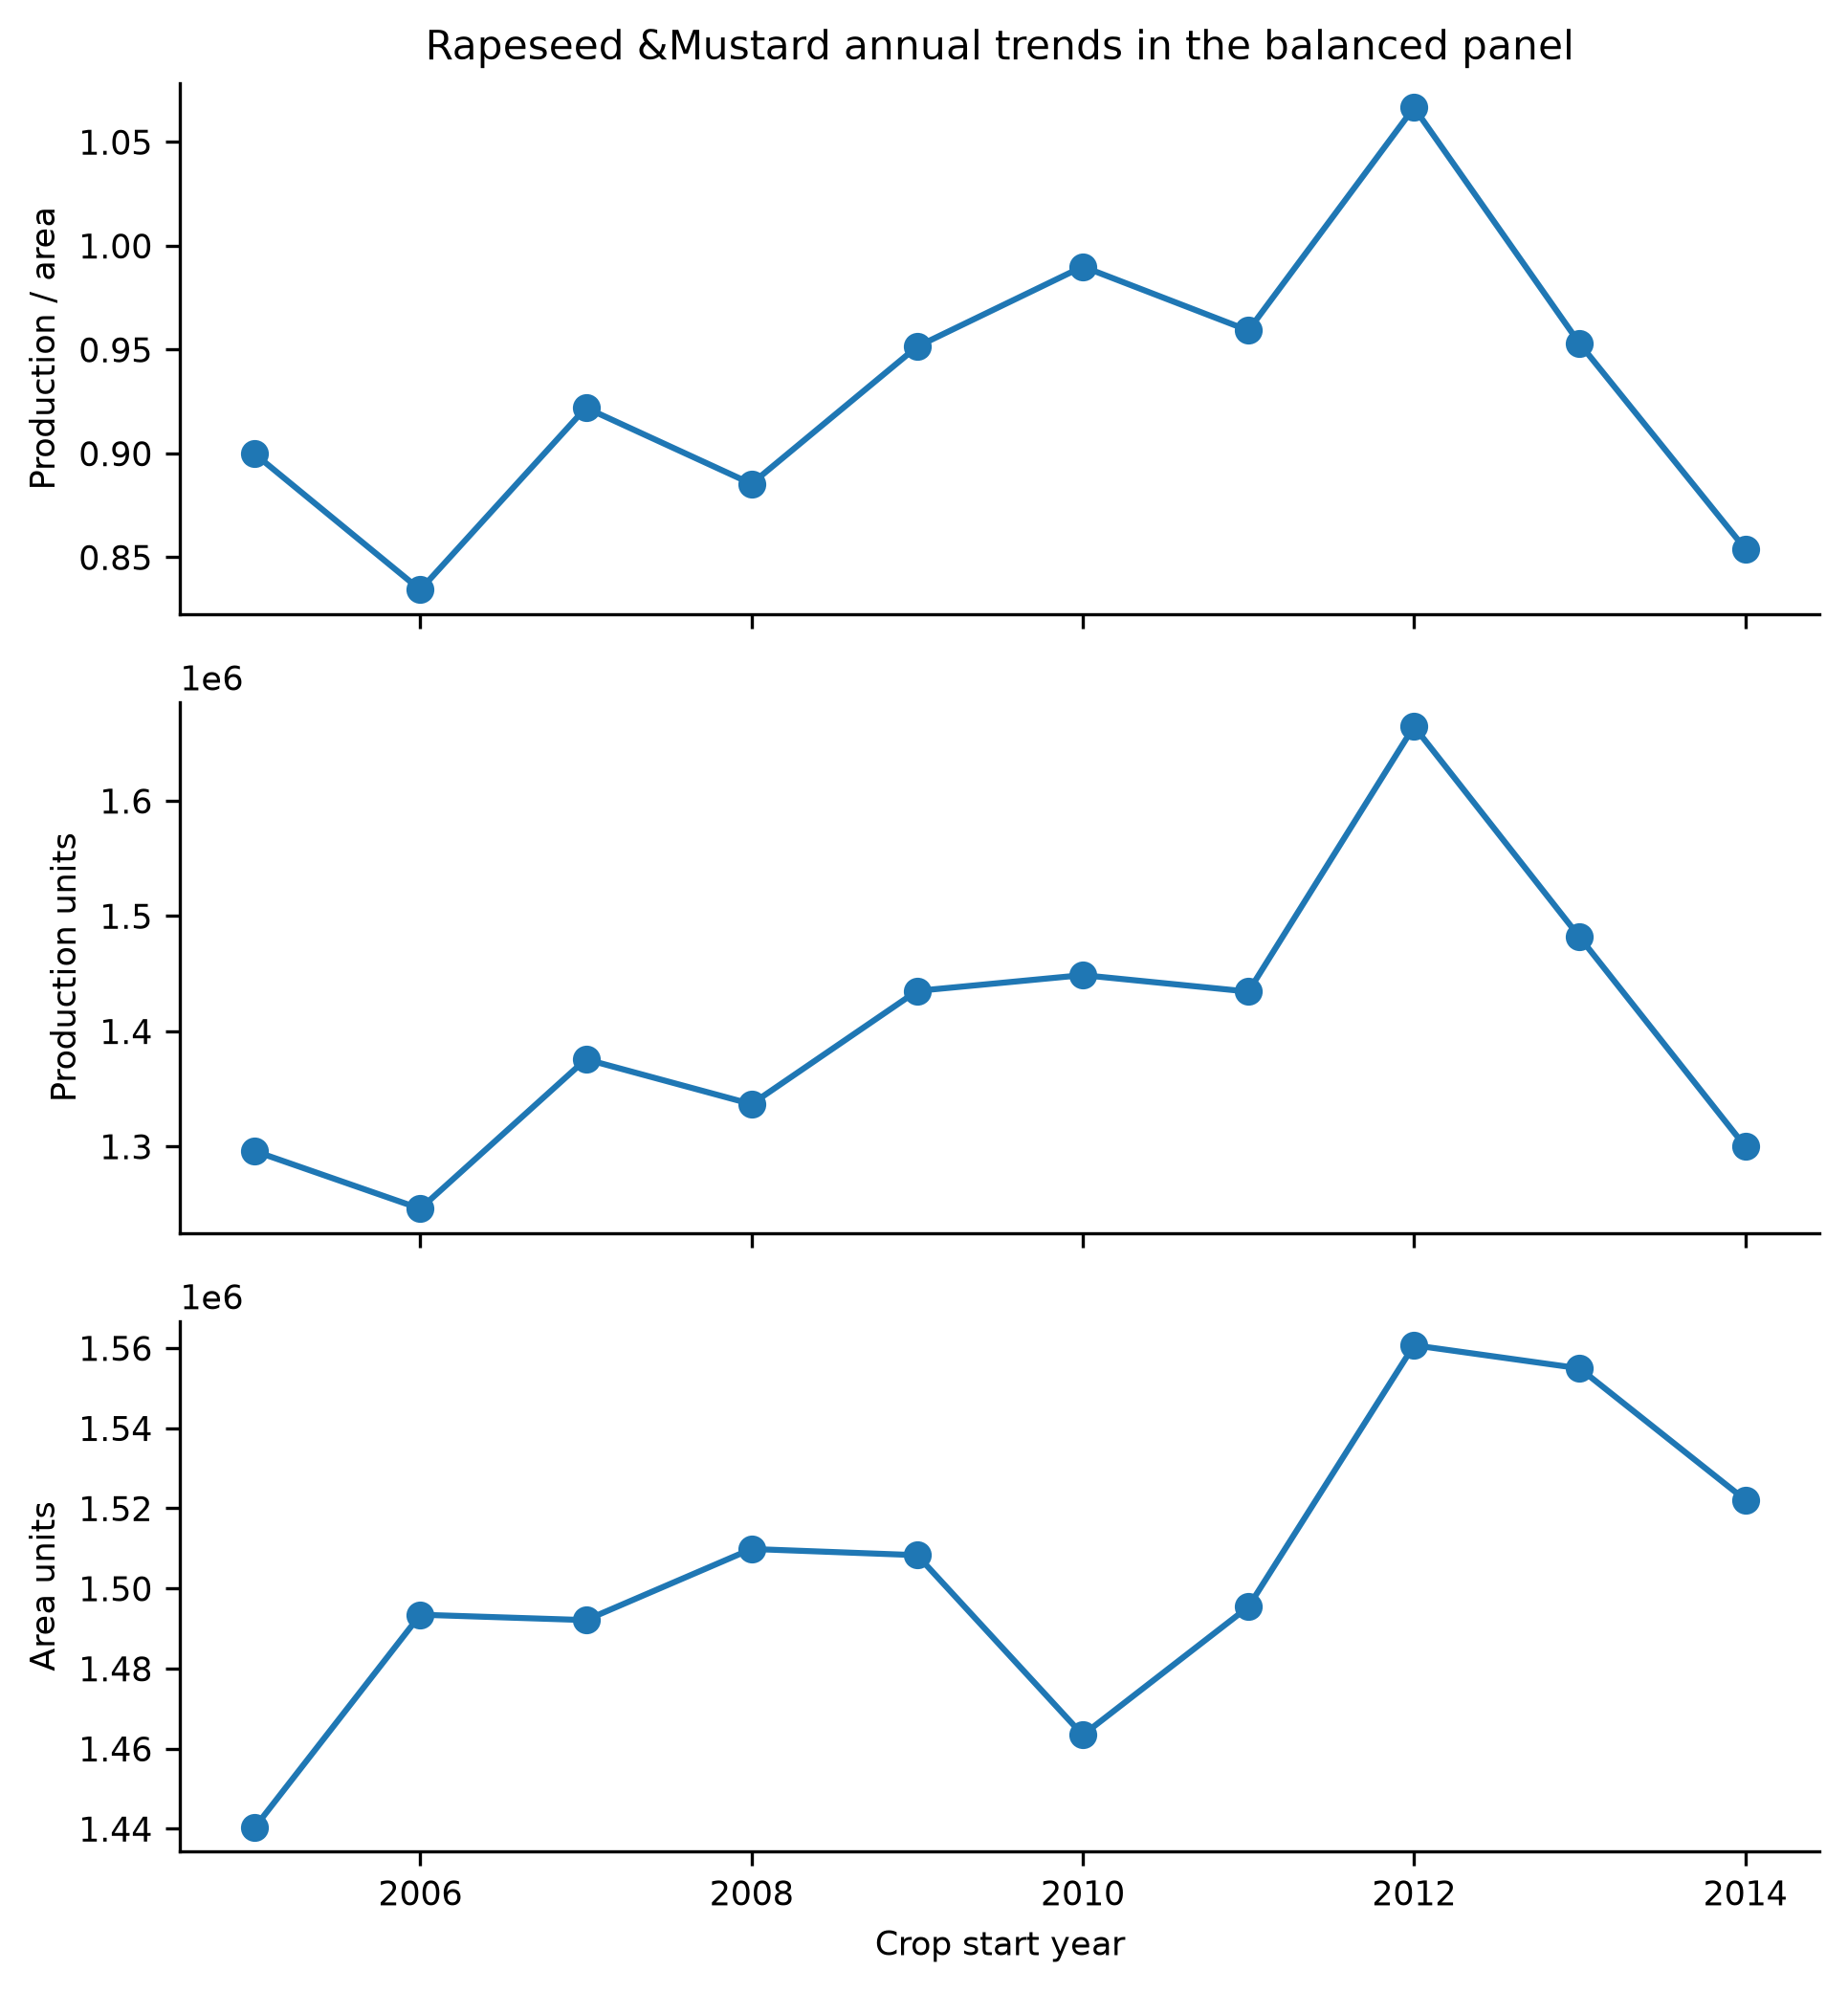

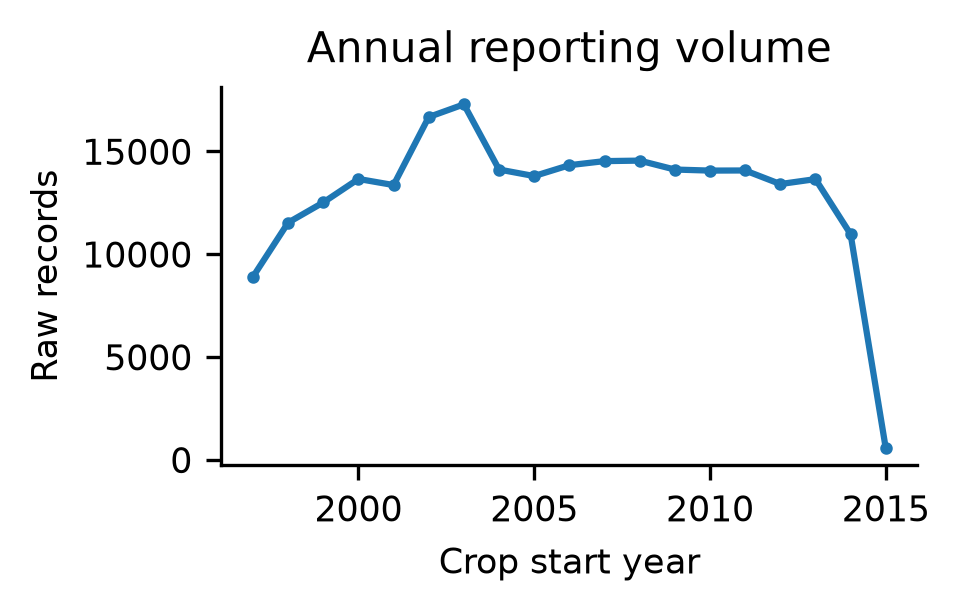

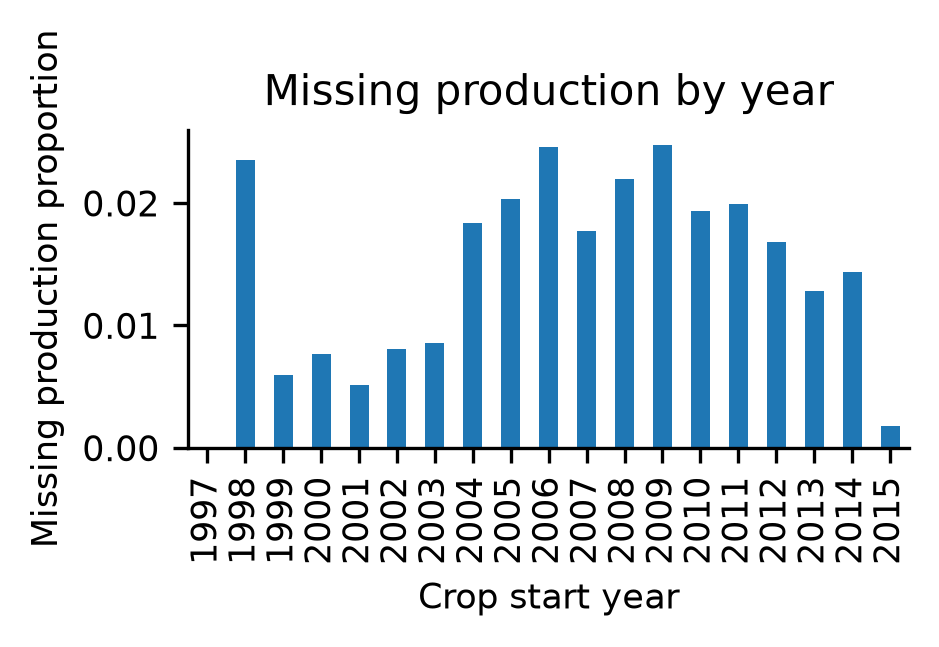

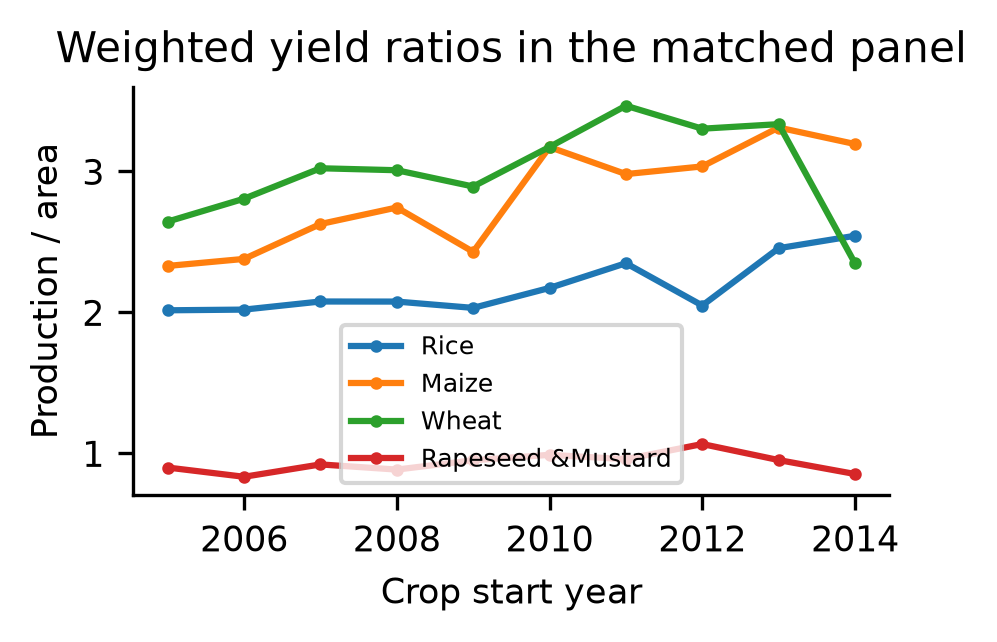

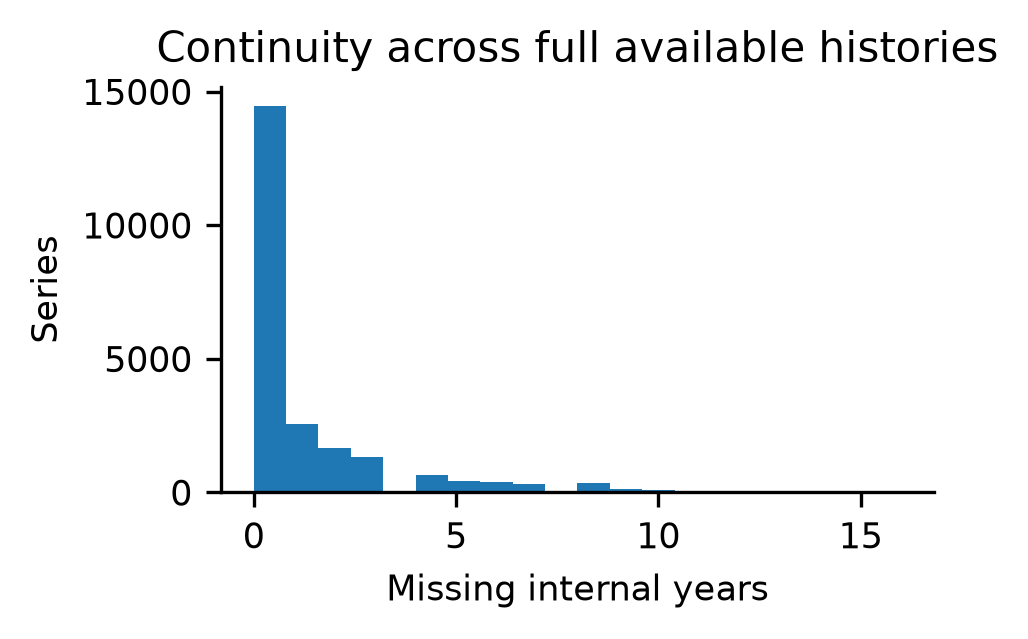

In [4]:
# Representative EDA uses matched districts; all non-modeling EDA can use full panel.
sel=panel[panel.sid.isin(ids)&panel.Crop_Year.between(2005,2014)]
pooled=sel.groupby(['Crop','Crop_Year'])[['area','production']].sum();pooled['yield_ratio']=pooled.production/pooled.area;pooled.to_csv(ROOT/'weighted_crop_series.csv')
for crop in CROPS:
 annual=pooled.loc[crop];fig,ax=plt.subplots(3,1,figsize=(6.6,7),sharex=True)
 for axis,col,lab in zip(ax,['yield_ratio','production','area'],['Production / area','Production units','Area units']):annual[col].plot(ax=axis,marker='o');axis.set_ylabel(lab)
 ax[0].set_title(crop+' annual trends in the balanced panel');ax[-1].set_xlabel('Crop start year');save('trends_'+crop.split()[0])
fig,ax=plt.subplots(figsize=(3.3,2.1));s=d.Crop_Year.value_counts().sort_index();ax.plot(s.index,s.values,marker='o',ms=2);ax.set(xlabel='Crop start year',ylabel='Raw records',title='Annual reporting volume');save('reporting')
fig,ax=plt.subplots(figsize=(3.3,2.1));d.isna().groupby(d.Crop_Year).mean().Production.plot.bar(ax=ax);ax.set(ylabel='Missing production proportion',xlabel='Crop start year',title='Missing production by year');save('missingness')
fig,ax=plt.subplots(figsize=(3.3,2.2))
for crop in CROPS:pooled.loc[crop].yield_ratio.plot(ax=ax,marker='o',ms=2,label=crop)
ax.set(xlabel='Crop start year',ylabel='Production / area',title='Weighted yield ratios in the matched panel');ax.legend(fontsize=6);save('yield_trends')
fig,ax=plt.subplots(figsize=(3.3,2.2));cov['missing_internal_years'].plot.hist(ax=ax,bins=20);ax.set(xlabel='Missing internal years',ylabel='Series',title='Continuity across full available histories');save('coverage')




## 5 Pre-test stationarity and dependence

STATIONARITY 769


Diagnostic warnings captured and exported: 4007


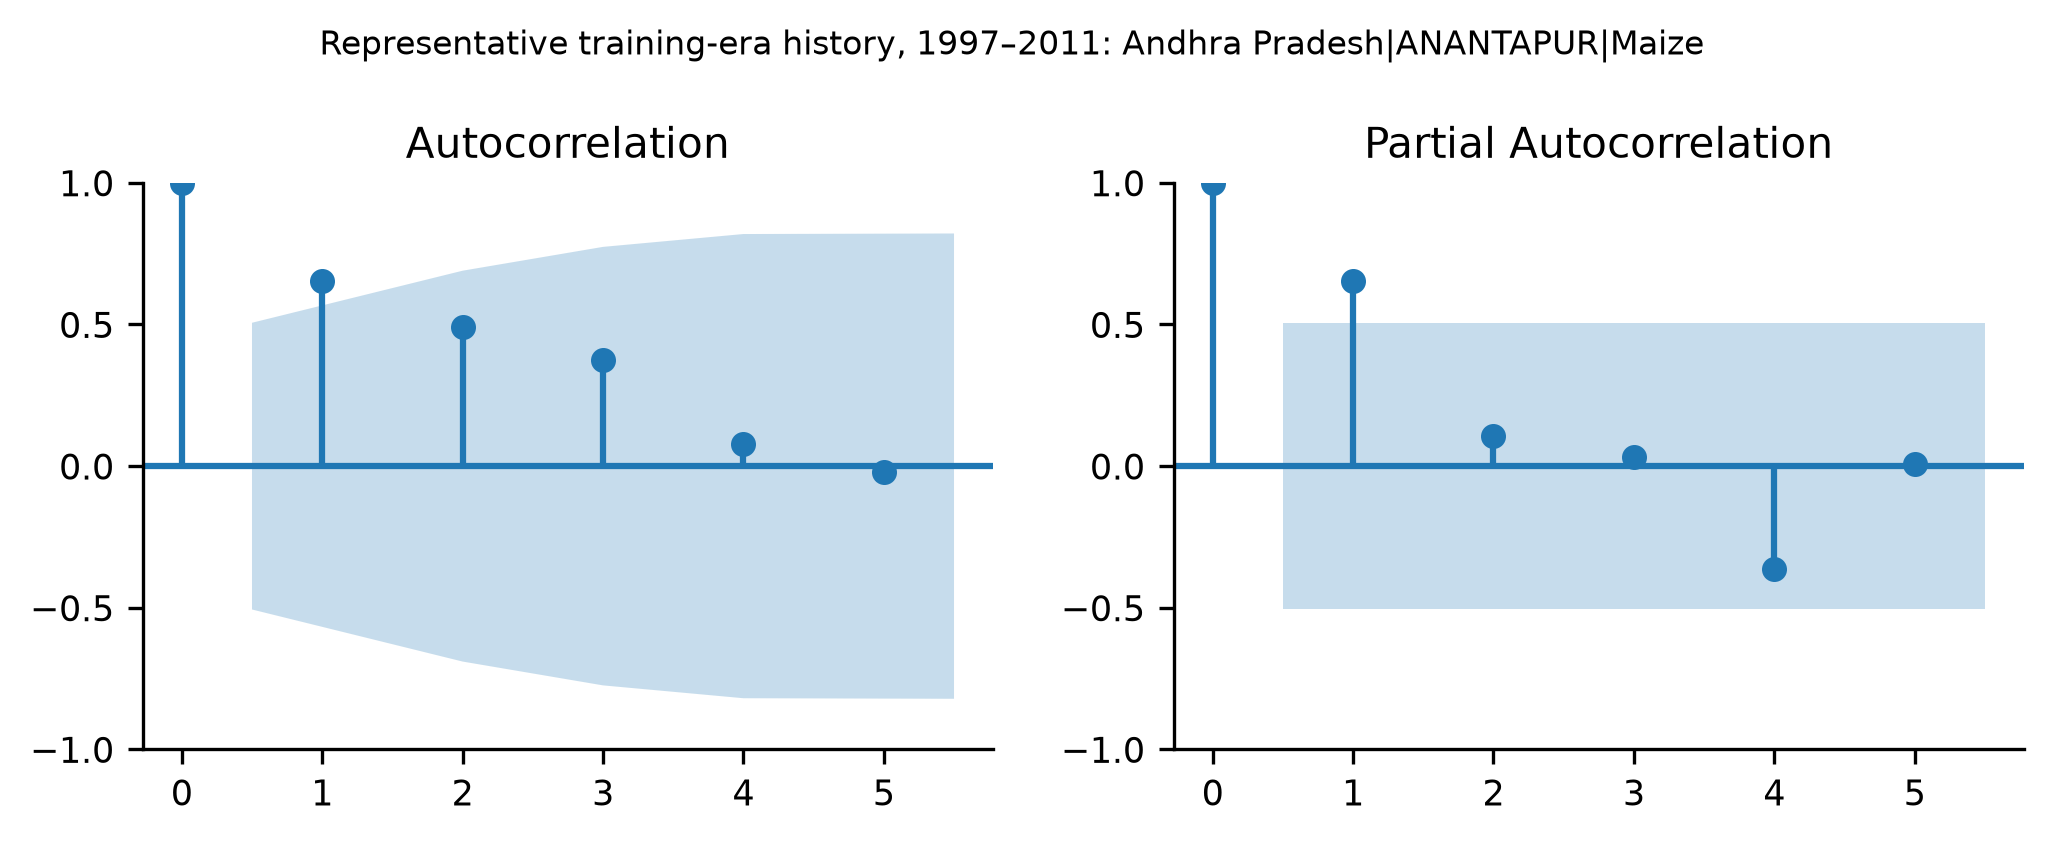

In [5]:
# Training-only diagnostics on longest complete 1997-2011 histories for the selected identities.
long=panel[panel.sid.isin(ids)].pivot(index='sid',columns='Crop_Year',values='y').reindex(columns=list(range(1997,2012))).dropna()
station=[]; diagnostic_warnings=[]
for sid,r in long.iterrows():
 for transform,v in [('level',r.values),('difference',np.diff(r.values))]:
  try:
   with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter('always')
    a=adfuller(v,maxlag=1,autolag='AIC');k=kpss(v,regression='c',nlags='auto')
   diagnostic_warnings.extend({'sid':sid,'transform':transform,'category':type(w.message).__name__,'message':str(w.message)} for w in captured)
   station.append({'sid':sid,'transform':transform,'n':len(v),'adf_stat':a[0],'adf_p':a[1],'kpss_stat':k[0],'kpss_p':k[1]})
  except Exception as ex:station.append({'sid':sid,'transform':transform,'error':str(ex)})
station=pd.DataFrame(station);station.to_csv(ROOT/'stationarity_results.csv',index=False)
print('STATIONARITY',len(long),flush=True)
pd.DataFrame(diagnostic_warnings,columns=['sid','transform','category','message']).to_csv(ROOT/'diagnostic_warnings.csv',index=False)
print('Diagnostic warnings captured and exported:',len(diagnostic_warnings))
if len(long):
 representative=long.iloc[0]
 fig,axes=plt.subplots(1,2,figsize=(7,2.8))
 plot_acf(representative.values,lags=5,ax=axes[0]);plot_pacf(representative.values,lags=5,method='ywm',ax=axes[1])
 fig.suptitle('Representative training-era history, 1997–2011: '+str(long.index[0]),fontsize=8)
 save('training_acf_pacf')





## 6 Baselines and classical implementations
The classical estimators use past observations only. Fixed-origin forecasts retain the same fitted states or coefficients for all horizons. Unconstrained AR(1) can be unstable and produce extreme or negative forecasts; those results remain visible.

In [6]:
# Models: local baseline methods, a transparent OLS AR(1), and custom least-squares smoothing.
NAMES=['Naive','Mean','MA3','Drift','AR1_OLS','SES_LS','Holt_LS','DampedHolt_LS']
fitlog=[]
def smooth(h,alpha,beta=0,phi=1,kind='SES'):
 l=float(h[0]);b=0 if kind=='SES' else float(h[1]-h[0]);sse=0;res=[]
 for v in h[1:]:
  pr=l+phi*b;e=float(v-pr);res.append(e);sse+=e*e
  ln=alpha*v+(1-alpha)*pr
  b=0 if kind=='SES' else beta*(ln-l)+(1-beta)*phi*b
  l=ln
 return sse,l,b,np.array(res)
def fit(name,h):
 h=np.asarray(h,dtype=float);n=len(h)
 if name=='Naive':return lambda H:np.repeat(h[-1],H),{},None
 if name=='Mean':return lambda H:np.repeat(h.mean(),H),{},None
 if name=='MA3':return lambda H:np.repeat(h[-3:].mean(),H),{'window':3},None
 if name=='Drift':return lambda H:h[-1]+np.arange(1,H+1)*(h[-1]-h[0])/(n-1),{},None
 if name=='AR1_OLS':
  X=np.column_stack([np.ones(n-1),h[:-1]]);c,phi=np.linalg.lstsq(X,h[1:],rcond=None)[0]
  def fc(H):
   ans=[];v=h[-1]
   for _ in range(H):v=c+phi*v;ans.append(v)
   return np.array(ans)
  return fc,{'constant':c,'phi':phi},h[1:]-X@np.array([c,phi])
 kind='SES' if name=='SES_LS' else 'Holt';damped=name=='DampedHolt_LS'
 x0=[.5] if kind=='SES' else ([.5,.2,.9] if damped else [.5,.2])
 bounds=[(.01,.99)] if kind=='SES' else ([(.01,.99),(.01,.99),(.8,.98)] if damped else [(.01,.99),(.01,.99)])
 def unpack(p):return p[0],(0 if kind=='SES' else p[1]),(p[2] if damped else 1)
 opt=minimize(lambda p:smooth(h,*unpack(p),kind=kind)[0],x0,bounds=bounds,method='L-BFGS-B',options={'maxiter':150})
 a,b,phi=unpack(opt.x);_,level,trend,res=smooth(h,a,b,phi,kind=kind)
 def fc(H):return np.array([level+trend*sum(phi**j for j in range(1,i+1)) for i in range(1,H+1)])
 return fc,{'alpha':a,'beta':b,'phi':phi,'optimizer_success':bool(opt.success),'optimizer_message':str(opt.message)},res
failures=[];timings=[]
def local_predictions(years,mode):
 records=[]
 for name in NAMES:
  tic=time.perf_counter()
  for sid,r in wide.iterrows():
   origins=[2011] if mode=='fixed_origin' else [yr-1 for yr in years]
   for origin in origins:
    try:
     fc,params,res=fit(name,r.loc[:origin].values)
     fitlog.append({'model':name,'sid':sid,'origin':origin,'mode':mode,**params})
     yrs=years if mode=='fixed_origin' else [origin+1];pred=fc(len(yrs))
     if not np.isfinite(pred).all():raise ValueError('Nonfinite predictions')
     for yr,v in zip(yrs,pred):records.append({'model':name,'sid':sid,'year':yr,'horizon':yr-origin,'mode':mode,'actual':r[yr],'prediction':float(v)})
    except Exception as ex:failures.append({'model':name,'sid':sid,'origin':origin,'mode':mode,'error':str(ex)})
  timings.append({'model':name,'mode':mode,'targets':str(years),'seconds':time.perf_counter()-tic})
  print(mode,name,'done',round(time.perf_counter()-tic,2),flush=True)
 return pd.DataFrame(records)
FEATURES=['lag1','lag2','lag3','mean3','std3','time']
def feat(h,yr):h=np.asarray(h);return [h[-1],h[-2],h[-3],h[-3:].mean(),h[-3:].std(),yr-2005]
def xy(end):
 X=[];Y=[]
 for _,r in wide.iterrows():
  for yr in range(2008,end+1):X.append(feat(r.loc[:yr-1],yr));Y.append(r[yr])
 return np.array(X),np.array(Y)
PARAMS=[dict(n_estimators=150,max_depth=2,learning_rate=.05,subsample=.8,colsample_bytree=.9,reg_lambda=5),dict(n_estimators=250,max_depth=3,learning_rate=.03,subsample=.8,colsample_bytree=.9,reg_lambda=10)]
def make_xgb(params):return XGBRegressor(**params,objective='reg:squarederror',random_state=42,n_jobs=2)
def xp(params,years,name,mode):
 records=[];tic=time.perf_counter()
 origins=[2011] if mode=='fixed_origin' else [yr-1 for yr in years]
 for origin in origins:
  X,Y=xy(origin);m=make_xgb(params).fit(X,Y)
  for sid,r in wide.iterrows():
   history=r.loc[:origin].tolist();yrs=years if mode=='fixed_origin' else [origin+1]
   for yr in yrs:
    v=float(m.predict(np.array([feat(history,yr)]))[0]);records.append({'model':name,'sid':sid,'year':yr,'horizon':yr-origin,'mode':mode,'actual':r[yr],'prediction':v});history.append(v)
 timings.append({'model':name,'mode':mode,'targets':str(years),'seconds':time.perf_counter()-tic})
 return pd.DataFrame(records)
scales=wide.loc[:,:2009].diff(axis=1).abs().mean(axis=1) # validation scaling uses only initial training
def score(pred,expected):
 ans=[]
 for name,g in pred.groupby('model'):
  if len(g)!=expected or g.duplicated(['sid','year']).any() or not np.isfinite(g.prediction).all():continue
  a=g.actual.to_numpy();p=g.prediction.to_numpy();e=a-p;valid=np.abs(a)>1e-8;den=np.abs(a)+np.abs(p);sc=g.sid.map(scales).to_numpy();ms=sc>1e-8
  ans.append({'model':name,'n':len(g),'MAE':abs(e).mean(),'RMSE':np.sqrt((e**2).mean()),'MAPE':100*np.mean(abs(e[valid]/a[valid])) if valid.any() else None,'MAPE_n':int(valid.sum()),'sMAPE':np.mean(np.divide(200*abs(e),den,out=np.zeros_like(e),where=den>1e-8)),'MASE':np.mean(abs(e[ms])/sc[ms]) if ms.any() else None,'MFE':e.mean()})
 return pd.DataFrame(ans).sort_values('RMSE')


## 7 Small neural architectures and training protocol
All inputs are three historical yields. Each fit normalizes on its training observations only. Inner fitting ends in 2008 and selects an epoch using 2009 with patience 8 and a 60-epoch ceiling. The selected epoch count stays fixed for outer 2010–2011 validation and subsequent test refits. Training-row shuffling occurs only within the already chronological training split. The patch Transformer uses length-two overlapping patches, positional embeddings and two attention heads; it is not an exact PatchTST reproduction.

In [7]:
"""Small CPU neural models with training-only normalization and nested stopping."""
import time,copy,random,json
import numpy as np
import torch
from torch import nn

torch.set_num_threads(2)
torch.backends.mkldnn.enabled=False
class TinySequence(nn.Module):
 def __init__(self,kind,hidden=16,dropout=.1):
  super().__init__();self.kind=kind
  if kind=='LSTM':self.rnn=nn.LSTM(1,hidden,batch_first=True)
  elif kind=='GRU':self.rnn=nn.GRU(1,hidden,batch_first=True)
  else:
   self.patch=nn.Linear(2,8);self.position=nn.Parameter(torch.randn(1,2,8)*.02)
   self.encoder=nn.TransformerEncoder(nn.TransformerEncoderLayer(8,2,16,dropout,batch_first=True,norm_first=True),1,enable_nested_tensor=False)
  self.dropout=nn.Dropout(dropout);self.head=nn.Linear(16 if kind=='PatchTransformerTiny' else hidden,1)
 def forward(self,x):
  if self.kind=='PatchTransformerTiny':
   patches=x.squeeze(-1).unfold(1,2,1);h=self.encoder(self.patch(patches)+self.position).flatten(1)
  else:h=self.rnn(x)[0][:,-1,:]
  return self.head(self.dropout(h)).squeeze(-1)
def seed_all(seed=42):
 random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.use_deterministic_algorithms(True)
def sequences(wide,end):
 X=[];Y=[];ident=[]
 for sid,r in wide.iterrows():
  for yr in range(2008,end+1):X.append(r.loc[yr-3:yr-1].values);Y.append(r[yr]);ident.append((sid,yr))
 return np.asarray(X,dtype=np.float32),np.asarray(Y,dtype=np.float32),ident
def forecast_inputs(wide,year):return np.stack([r.loc[year-3:year-1].values for _,r in wide.iterrows()]).astype(np.float32)
def train_model(wide,kind,end,epochs=60,inner_stop=False,checkpoint=None):
 seed_all(42);mu=float(wide.loc[:,:end].values.mean());sd=float(wide.loc[:,:end].values.std());sd=max(sd,1e-6)
 X,Y,ident=sequences(wide,end);xx=torch.tensor(((X-mu)/sd)[...,None]);yy=torch.tensor((Y-mu)/sd)
 m=TinySequence(kind);optimizer=torch.optim.Adam(m.parameters(),lr=.003,weight_decay=1e-4);lossfn=nn.MSELoss();trace=[];best=float('inf');beststate=None;bestepoch=0;stale=0;tic=time.perf_counter();initial=copy.deepcopy(m.state_dict())
 if inner_stop:
  assert end==2008
  vx=torch.tensor(((forecast_inputs(wide,2009)-mu)/sd)[...,None]);vy=torch.tensor((wide[2009].values.astype(np.float32)-mu)/sd)
 for ep in range(1,epochs+1):
  m.train();order=torch.randperm(len(xx));total=0
  for start in range(0,len(xx),256):
   idx=order[start:start+256];optimizer.zero_grad();pred=m(xx[idx]);loss=lossfn(pred,yy[idx]);assert torch.isfinite(loss)
   loss.backward();nn.utils.clip_grad_norm_(m.parameters(),1.0);optimizer.step();total+=float(loss.detach())*len(idx)
  m.eval()
  with torch.no_grad():valid=float(lossfn(m(vx),vy)) if inner_stop else None
  trace.append({'epoch':ep,'train_normalized_MSE':total/len(xx),'validation_normalized_MSE':valid})
  if inner_stop:
   if valid<best-1e-6:best=valid;beststate=copy.deepcopy(m.state_dict());bestepoch=ep;stale=0
   else:stale+=1
   if stale>=8:break
 if inner_stop:m.load_state_dict(beststate)
 else:bestepoch=epochs
 assert any(not torch.equal(initial[k],m.state_dict()[k]) for k in initial),'Weights did not change'
 pack={'state_dict':m.state_dict(),'mu':mu,'sd':sd,'kind':kind,'end':end,'epochs':bestepoch}
 if checkpoint is not None:torch.save(pack,checkpoint)
 return m,pack,trace,{'kind':kind,'origin':end,'epochs_run':len(trace),'selected_epochs':bestepoch,'parameter_count':sum(p.numel() for p in m.parameters()),'training_sequences':len(xx),'normalization_mean':mu,'normalization_std':sd,'train_seconds':time.perf_counter()-tic,'max_training_target_year':max(y for _,y in ident),'inner_stop_year':2009 if inner_stop else None}
def predict_batch(model,pack,X):
 model.eval()
 with torch.no_grad():return model(torch.tensor(((np.asarray(X,dtype=np.float32)-pack['mu'])/pack['sd'])[...,None])).numpy().astype(float)*pack['sd']+pack['mu']
def verify_checkpoint(path,X):
 p=torch.load(path,map_location='cpu',weights_only=True);m=TinySequence(p['kind']);m.load_state_dict(p['state_dict']);return predict_batch(m,p,X)


## 8 Expanded XGBoost chronological tuning
The two previous candidates and ten seeded configurations vary depth, estimators, learning rate, subsampling and regularization. Only validation RMSE chooses the candidate; test results never change it.

In [8]:
import torch,copy,logging,traceback,importlib.metadata as pkg
(RootModels:=ROOT/'models').mkdir(exist_ok=True)
model_status={};training_records=[];test_cache={};inner_epochs={};trial_records=[]
# Expanded XGBoost search: two previous settings plus ten seeded candidates.
rng=np.random.default_rng(42)
CANDIDATES=list(PARAMS)
while len(CANDIDATES)<12:
 p={'n_estimators':int(rng.choice([100,200,350])),'max_depth':int(rng.choice([2,3,4])),'learning_rate':float(rng.choice([.03,.05,.08])),'subsample':float(rng.choice([.7,.85,1.])),'colsample_bytree':float(rng.choice([.7,.9,1.])),'reg_lambda':float(rng.choice([1.,5.,10.])),'reg_alpha':float(rng.choice([0.,.1,1.])),'min_child_weight':int(rng.choice([1,5,10]))}
 if p not in CANDIDATES:CANDIDATES.append(p)
def xgb_eval(params,years,name,mode):
 records=[];models={}
 for origin in ([2011] if mode=='fixed_origin' else [y-1 for y in years]):
  X,Y=xy(origin);tic=time.perf_counter();m=XGBRegressor(**params,objective='reg:squarederror',random_state=42,n_jobs=2).fit(X,Y)
  training_records.append({'model':name,'origin':origin,'mode':mode,'train_seconds':time.perf_counter()-tic,'training_rows':len(Y)})
  models[origin]=m;hist=wide.loc[:,:origin].values.copy();yrs=years if mode=='fixed_origin' else [origin+1]
  for year in yrs:
   Xp=np.array([feat(h,year) for h in hist]);tinf=time.perf_counter();pr=m.predict(Xp)
   training_records.append({'model':name,'origin':origin,'mode':mode,'inference_seconds':time.perf_counter()-tinf,'inference_rows':len(pr)})
   for sid,v in zip(wide.index,pr):records.append({'model':name,'sid':sid,'year':year,'horizon':year-origin,'mode':mode,'actual':wide.loc[sid,year],'prediction':float(v)})
   hist=np.column_stack([hist,pr])
 return pd.DataFrame(records),models
scales=wide.loc[:,:2009].diff(axis=1).abs().mean(axis=1)
val=local_predictions([2010,2011],'validation_one_step')
trial_predictions={}
for i,params in enumerate(CANDIDATES):
 try:
  pr,_=xgb_eval(params,[2010,2011],f'XGB_trial_{i:02d}','validation_one_step');metric=score(pr,len(wide)*2).iloc[0].to_dict();trial_records.append({'trial':i,'status':'completed',**params,**metric});trial_predictions[i]=pr
 except Exception as e:trial_records.append({'trial':i,'status':'failed',**params,'error':str(e)})
 print('XGBoost trial',i,'done',flush=True)
trials=pd.DataFrame(trial_records);trials.to_csv(ROOT/'hyperparameter_results.csv',index=False)
valid_trials=trials[trials.status.eq('completed')];chosen_trial=int(valid_trials.sort_values(['RMSE','trial']).iloc[0].trial);chosen_xgb=CANDIDATES[chosen_trial]
xval=trial_predictions[chosen_trial].copy();xval['model']='XGBoost_Tuned';val=pd.concat([val,xval],ignore_index=True)
js('xgboost_selection.json',{'trial_count':len(CANDIDATES),'selected_trial':chosen_trial,'parameters':chosen_xgb,'criterion':'expanding validation RMSE, 2010 and 2011','seed':42})


validation_one_step Naive done 0.1


validation_one_step Mean done 0.11


validation_one_step

 MA3 done 0.1


validation_one_step

 Drift done 0.11


... (12 outputs left out)

XGBoost trial 8 done


XGBoost trial 9 done


XGBoost trial 10 done


XGBoost trial 11 done


## 9 Neural inner stopping and chronological outer validation

In [9]:
# Inner 2009 stopping year is earlier than both outer validation targets.
for kind in ['LSTM','GRU','PatchTransformerTiny']:
 try:
  m,pack,trace,rec=train_model(wide,kind,2008,epochs=60,inner_stop=True,checkpoint=RootModels/(kind+'_inner.pt'));inner_epochs[kind]=pack['epochs'];training_records.append({'model':kind,'mode':'inner_stopping',**rec})
  pd.DataFrame(trace).to_csv(ROOT/(kind+'_loss.csv'),index=False)
  records=[]
  for year in [2010,2011]:
   mm,pp,tt,rr=train_model(wide,kind,year-1,epochs=inner_epochs[kind],checkpoint=RootModels/f'{kind}_validation_{year-1}.pt');training_records.append({'model':kind,'mode':'validation_one_step',**rr})
   pred=predict_batch(mm,pp,forecast_inputs(wide,year))
   for sid,v in zip(wide.index,pred):records.append({'model':kind,'sid':sid,'year':year,'horizon':1,'mode':'validation_one_step','actual':wide.loc[sid,year],'prediction':float(v)})
  val=pd.concat([val,pd.DataFrame(records)],ignore_index=True);model_status[kind]={'status':'validation completed','selected_epochs':inner_epochs[kind],'parameter_count':rec['parameter_count'],'lookback':3,'normalization':'fit separately on each training origin','inner_train_end':2008,'inner_stop_year':2009,'max_epochs':60,'patience':8,'dropout':.1,'learning_rate':.003,'batch_size':256}
 except Exception as e:model_status[kind]={'status':'excluded after failure','error':str(e),'traceback':traceback.format_exc()}
 print('Neural validation',kind,model_status[kind]['status'],flush=True)
vl=score(val,len(wide)*2);best=vl.sort_values(['RMSE','model']).iloc[0].model
js('selection_frozen.json',{'best_model':best,'criterion':'outer expanding validation RMSE','test_evaluation_started':False,'test_limitation':'retrospective extension; these test years were examined in the prior archived study; no independent prospective holdout claimed'})
val.to_csv(ROOT/'validation_predictions.csv',index=False);vl.to_csv(ROOT/'validation_leaderboard.csv',index=False)
print('FROZEN OVERALL WINNER',best,flush=True)


Neural validation LSTM validation completed


Neural validation GRU validation completed


Neural validation PatchTransformerTiny validation completed


FROZEN OVERALL WINNER XGBoost_Tuned


## 10 Frozen selection and final tests

In [10]:
# No further tuning takes place after this point.
scales=wide.loc[:,:2011].diff(axis=1).abs().mean(axis=1)
test=local_predictions([2012,2013,2014],'test_one_step');fixed=local_predictions([2012,2013,2014],'fixed_origin')
xp_test,xmodels=xgb_eval(chosen_xgb,[2012,2013,2014],'XGBoost_Tuned','test_one_step');xp_fixed,_=xgb_eval(chosen_xgb,[2012,2013,2014],'XGBoost_Tuned','fixed_origin');test=pd.concat([test,xp_test],ignore_index=True);fixed=pd.concat([fixed,xp_fixed],ignore_index=True)
for kind in inner_epochs:
 try:
  records=[];models={}
  for year in [2012,2013,2014]:
   m,pack,trace,rec=train_model(wide,kind,year-1,epochs=inner_epochs[kind],checkpoint=RootModels/f'{kind}_test_origin_{year-1}.pt');training_records.append({'model':kind,'mode':'test_one_step',**rec});models[year-1]=(m,pack)
   Xp=forecast_inputs(wide,year);tic=time.perf_counter();pr=predict_batch(m,pack,Xp);training_records.append({'model':kind,'origin':year-1,'mode':'test_one_step','inference_seconds':time.perf_counter()-tic,'inference_rows':len(pr)})
   replay=verify_checkpoint(RootModels/f'{kind}_test_origin_{year-1}.pt',Xp[:5]);np.testing.assert_allclose(replay,pr[:5],atol=1e-7,rtol=1e-7)
   for sid,v in zip(wide.index,pr):records.append({'model':kind,'sid':sid,'year':year,'horizon':1,'mode':'test_one_step','actual':wide.loc[sid,year],'prediction':float(v)})
  test=pd.concat([test,pd.DataFrame(records)],ignore_index=True)
  m,pack=models[2011];hist=wide.loc[:,:2011].values.copy();records=[]
  for year in [2012,2013,2014]:
   pr=predict_batch(m,pack,hist[:,-3:])
   for sid,v in zip(wide.index,pr):records.append({'model':kind,'sid':sid,'year':year,'horizon':year-2011,'mode':'fixed_origin','actual':wide.loc[sid,year],'prediction':float(v)})
   hist=np.column_stack([hist,pr])
  fixed=pd.concat([fixed,pd.DataFrame(records)],ignore_index=True);model_status[kind]['status']='trained and evaluated';test_cache[kind]=models
 except Exception as e:model_status[kind].update(status='evaluation failed',error=str(e),traceback=traceback.format_exc())
for pred,stem in [(test,'test'),(fixed,'fixed_origin')]:
 lead=score(pred,len(wide)*3);lead['RMSE_improvement_vs_naive_pct']=100*(1-lead.RMSE/lead.set_index('model').loc['Naive','RMSE']);pred.to_csv(ROOT/(stem+'_predictions.csv'),index=False);lead.to_csv(ROOT/(stem+'_leaderboard.csv'),index=False)
 print(stem,'\n',lead.to_string(index=False),flush=True)
tl=pd.read_csv(ROOT/'test_leaderboard.csv');fl=pd.read_csv(ROOT/'fixed_origin_leaderboard.csv')
assert best in set(tl.model),'Validation-selected model failed testing; report selection failure rather than silently replacing it'


test_one_step Naive done 0.12


test_one_step Mean done 0.14


test_one_step MA3 done 0.16


test_one_step Drift done 0.14


test_one_step AR1_OLS done 0.31


test_one_step SES_LS done 2.88


... (8 outputs left out)

fixed_origin Holt_LS done 1.75


fixed_origin DampedHolt_LS done 2.2


test 
                model    n      MAE     RMSE      MAPE  MAPE_n     sMAPE      MASE       MFE  RMSE_improvement_vs_naive_pct
                LSTM 3336 0.326498 0.545658 23.561181    3335 19.470331  3.502827 -0.037365                       3.941651
PatchTransformerTiny 3336 0.325342 0.549615 22.665306    3335 18.992212  3.500578 -0.018564                       3.245089
                 GRU 3336 0.332123 0.551099 25.163281    3335 20.297188  3.606081 -0.059068                       2.983768
       XGBoost_Tuned 3336 0.336924 0.561743 24.765871    3335 19.705808  3.677039 -0.086381                       1.109914
               Naive 3336 0.329783 0.568048 20.656878    3335 18.654840  3.452378 -0.006888                       0.000000
              SES_LS 3336 0.342786 0.574474 21.166036    3335 19.332586  3.500811  0.037434                      -1.131109
                 MA3 3336 0.339886 0.579556 20.885357    3335 19.289012  3.887991  0.074899                      -2.025811
         

fixed_origin 
                model    n        MAE         RMSE         MAPE  MAPE_n     sMAPE         MASE       MFE  RMSE_improvement_vs_naive_pct
                LSTM 3336   0.355550     0.599152    24.597346    3335 20.859465     4.388052  0.000031                   3.223302e+00
PatchTransformerTiny 3336   0.349721     0.600379    22.797720    3335 19.970882     4.347584  0.024781                   3.025053e+00
                 GRU 3336   0.374230     0.600513    30.974900    3335 23.385214     4.538773 -0.068495                   3.003537e+00
               Naive 3336   0.364825     0.619108    22.374096    3335 21.023268     4.618771  0.050431                   0.000000e+00
       XGBoost_Tuned 3336   0.374807     0.628338    25.814324    3335 21.037627     4.540652 -0.091889                  -1.490819e+00
              SES_LS 3336   0.384164     0.634288    22.889710    3335 22.139248     4.717691  0.119148                  -2.451910e+00
                 MA3 3336   0.388431    

## 11 Selected-model refit and forecasts

In [11]:
# Refit only the validation-selected district-level model; keep classical and neural multistep forecasts origin-fixed.
future=[]
if best=='XGBoost_Tuned':
 X,Y=xy(2014);final=XGBRegressor(**chosen_xgb,objective='reg:squarederror',random_state=42,n_jobs=2).fit(X,Y);final.save_model(str(RootModels/'selected_xgboost.json'))
 pd.Series(final.feature_importances_,index=FEATURES).to_csv(ROOT/'feature_importance.csv');hist=wide.values.copy()
 for yr in [2015,2016,2017]:
  pr=final.predict(np.array([feat(h,yr) for h in hist]));hist=np.column_stack([hist,pr])
  for sid,v in zip(wide.index,pr):future.append({'sid':sid,'year':yr,'horizon':yr-2014,'forecast_yield_ratio':float(v),'model':best,'modeled_cutoff':2014})
elif best in inner_epochs:
 final,pack,trace,rec=train_model(wide,best,2014,epochs=inner_epochs[best],checkpoint=RootModels/'selected_neural.pt');training_records.append({'model':best,'mode':'future_refit',**rec});hist=wide.values.copy()
 for yr in [2015,2016,2017]:
  pr=predict_batch(final,pack,hist[:,-3:]);hist=np.column_stack([hist,pr])
  for sid,v in zip(wide.index,pr):future.append({'sid':sid,'year':yr,'horizon':yr-2014,'forecast_yield_ratio':float(v),'model':best,'modeled_cutoff':2014})
else:
 for sid,r in wide.iterrows():
  fc,pa,res=fit(best,r.values)
  for yr,v in zip([2015,2016,2017],fc(3)):future.append({'sid':sid,'year':yr,'horizon':yr-2014,'forecast_yield_ratio':float(v),'model':best,'modeled_cutoff':2014})
future=pd.DataFrame(future);future.to_csv(ROOT/'future_forecasts.csv',index=False)


## 12 Separate annual Prophet applicability experiment

In [12]:
# Prophet uses longer, stable-cohort annual crop aggregates: a different target population.
try:
 from prophet import Prophet
 logging.getLogger('cmdstanpy').setLevel(logging.WARNING)
 eligible_long=panel[panel.sid.isin(long.index)&panel.Crop_Year.between(1997,2014)]
 aggregate=eligible_long.groupby(['Crop','Crop_Year'])[['area','production']].sum();aggregate['y']=aggregate.production/aggregate.area;aggregate.to_csv(ROOT/'prophet_crop_series.csv')
 def prophet_predictions(prior,years,mode):
  records=[]
  for crop in CROPS:
   s=aggregate.loc[crop].y
   for origin in ([2011] if mode=='fixed_origin' else [y-1 for y in years]):
    tr=s.loc[:origin];frame=pd.DataFrame({'ds':pd.to_datetime(tr.index.astype(str)+'-01-01'),'y':tr.values});m=Prophet(daily_seasonality=False,weekly_seasonality=False,yearly_seasonality=False,n_changepoints=2,changepoint_prior_scale=prior,uncertainty_samples=0)
    m.fit(frame,seed=42);yrs=years if mode=='fixed_origin' else [origin+1];pr=m.predict(pd.DataFrame({'ds':pd.to_datetime([str(y)+'-01-01' for y in yrs])})).yhat.values
    for y,v in zip(yrs,pr):records.append({'model':'Prophet','crop':crop,'year':y,'horizon':y-origin,'mode':mode,'actual':s[y],'prediction':float(v)})
  return pd.DataFrame(records)
 pv=[];prior_predictions={}
 for prior in [.01,.05,.1]:
  pp=prophet_predictions(prior,[2010,2011],'validation_one_step');rmse=np.sqrt(np.mean((pp.actual-pp.prediction)**2));pv.append({'changepoint_prior_scale':prior,'validation_RMSE':rmse});prior_predictions[prior]=pp
 prior=min(pv,key=lambda x:x['validation_RMSE'])['changepoint_prior_scale'];pd.DataFrame(pv).to_csv(ROOT/'prophet_tuning.csv',index=False)
 prop_all=[]
 for mode in ['test_one_step','fixed_origin']:
  prop=prophet_predictions(prior,[2012,2013,2014],mode);prop_all.append(prop)
  for crop in CROPS:
   s=aggregate.loc[crop].y
   for year in [2012,2013,2014]:
    origin=2011 if mode=='fixed_origin' else year-1;h=s.loc[:origin].values
    for name in ['Naive','Mean','Drift']:
     fc,_,_=fit(name,h);prop_all.append(pd.DataFrame([{'model':name,'crop':crop,'year':year,'horizon':year-origin,'mode':mode,'actual':s[year],'prediction':float(fc(year-origin)[-1])}]))
 pp=pd.concat(prop_all,ignore_index=True);pp.to_csv(ROOT/'prophet_predictions.csv',index=False);rows=[]
 for (mode,model),g in pp.groupby(['mode','model']):
  a=g.actual.to_numpy();e=a-g.prediction.to_numpy();ok=np.abs(a)>1e-8;rows.append({'mode':mode,'model':model,'n':len(g),'MAE':np.mean(abs(e)),'RMSE':np.sqrt(np.mean(e**2)),'MAPE':100*np.mean(abs(e[ok]/a[ok]))})
 pd.DataFrame(rows).to_csv(ROOT/'prophet_separate_leaderboard.csv',index=False);model_status['Prophet']={'status':'trained and evaluated separately','target':'four crop aggregates from 769 stable histories, 1997–2014','daily_weekly_yearly_seasonality':False,'selected_changepoint_prior_scale':prior,'not_in_district_leaderboard':True,'uncertainty_intervals':'not calibrated; not exported'}
except Exception as e:model_status['Prophet']={'status':'excluded after runtime failure','error':str(e),'traceback':traceback.format_exc()}


Importing plotly failed. Interactive plots will not work.


C:\Users\mayan\Documents\Codex\2026-11-18\als\work\extended_deps\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
19:49:35 - cmdstanpy - INFO - Chain [1] start processing


19:49:36 - cmdstanpy - INFO - Chain [1] done processing


19:49:36 - cmdstanpy - ERROR - Chain [1] error: code '3236495362' 


## 13 Fit status, disaggregated errors and actual comparison plots

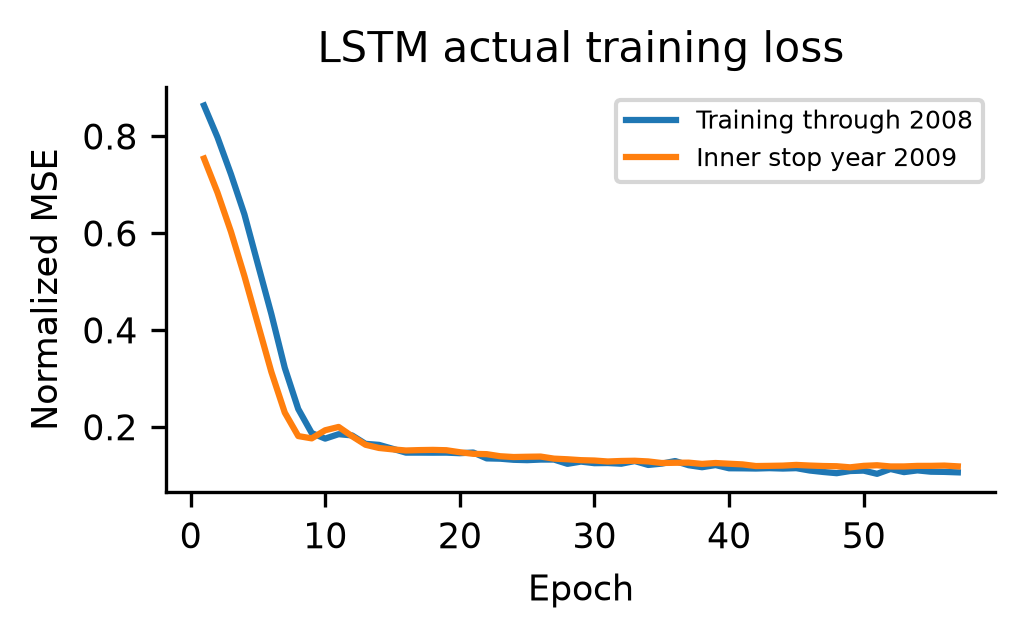

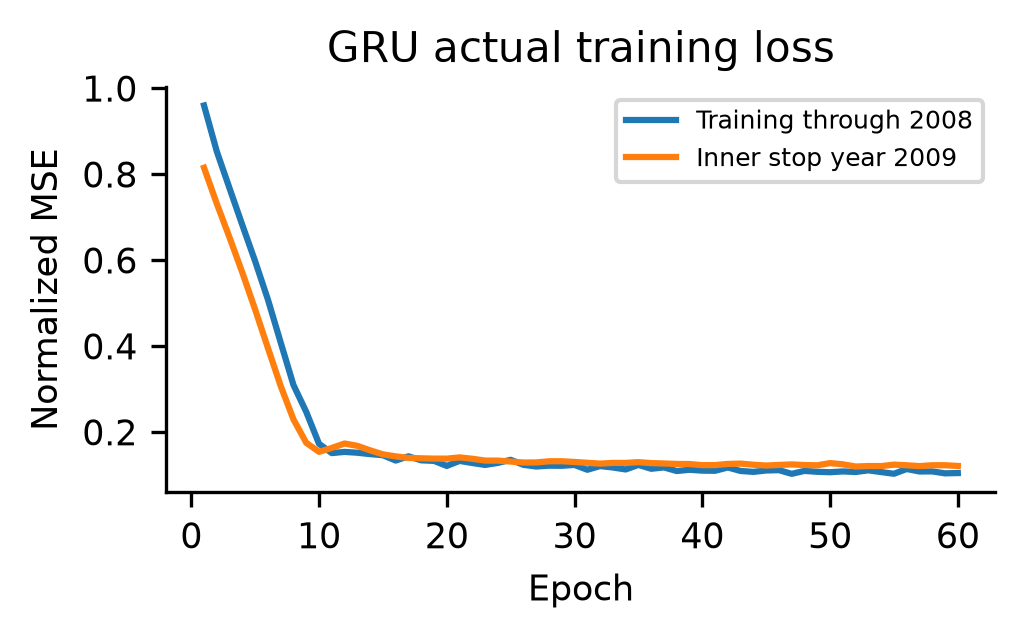

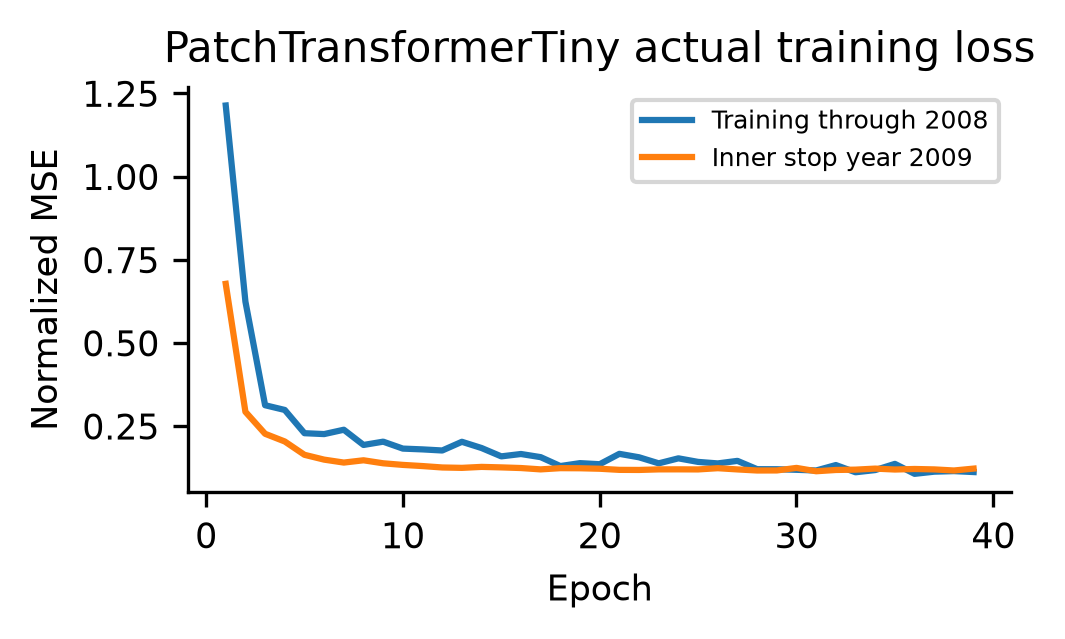

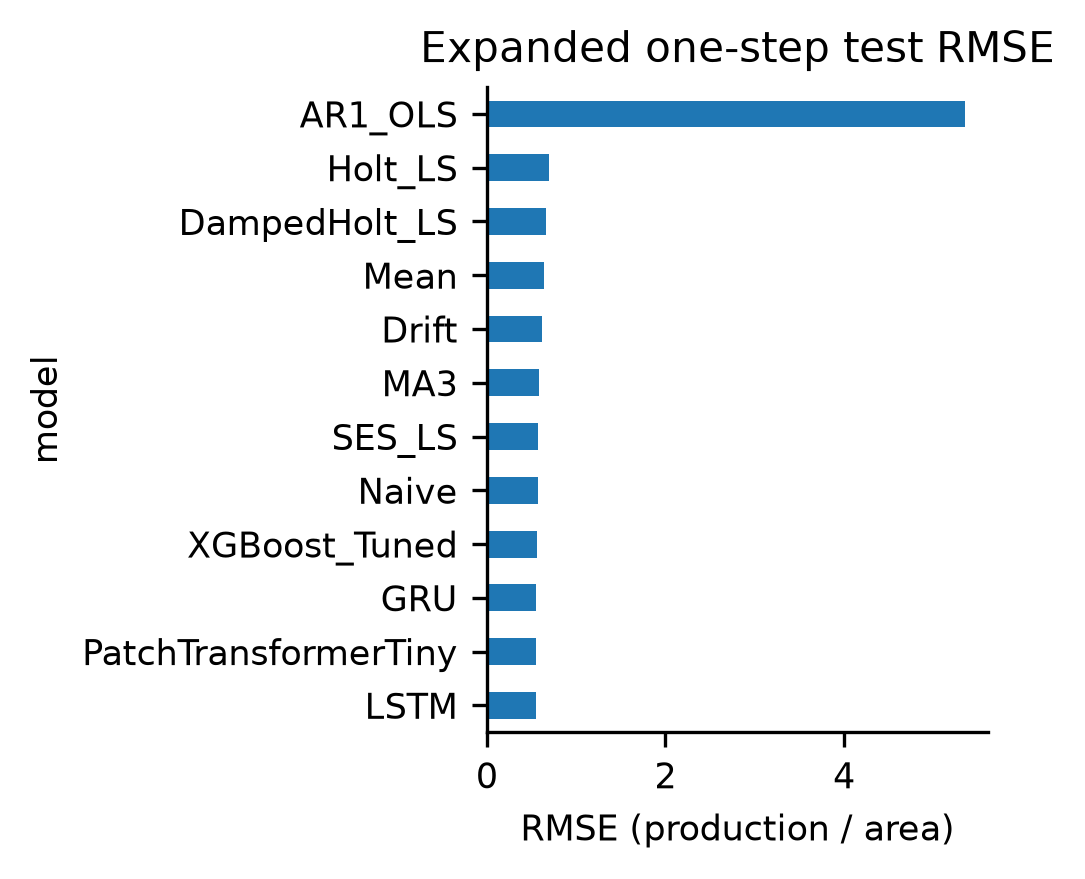

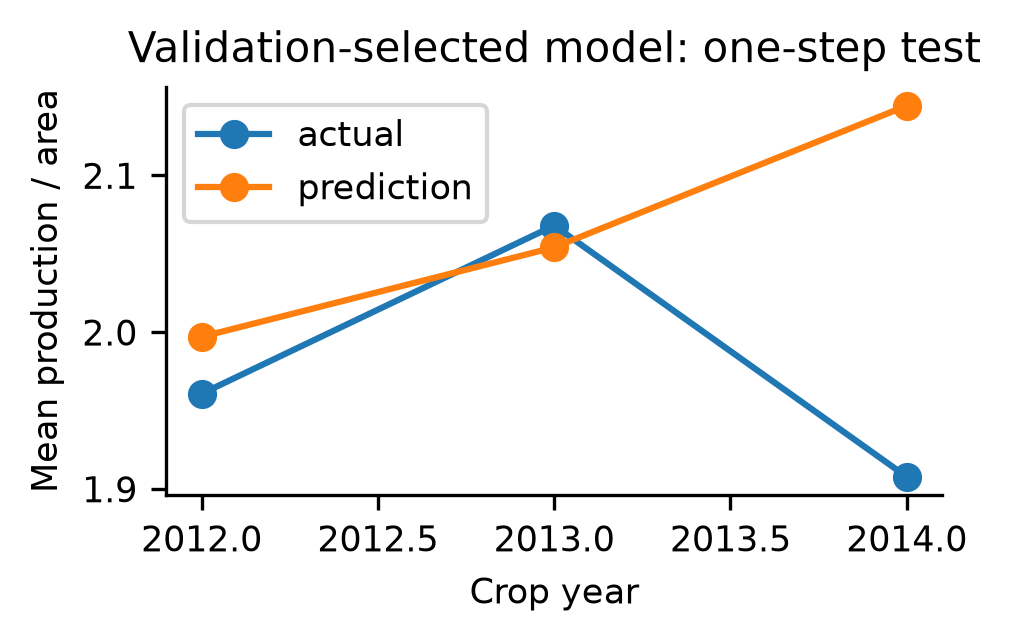

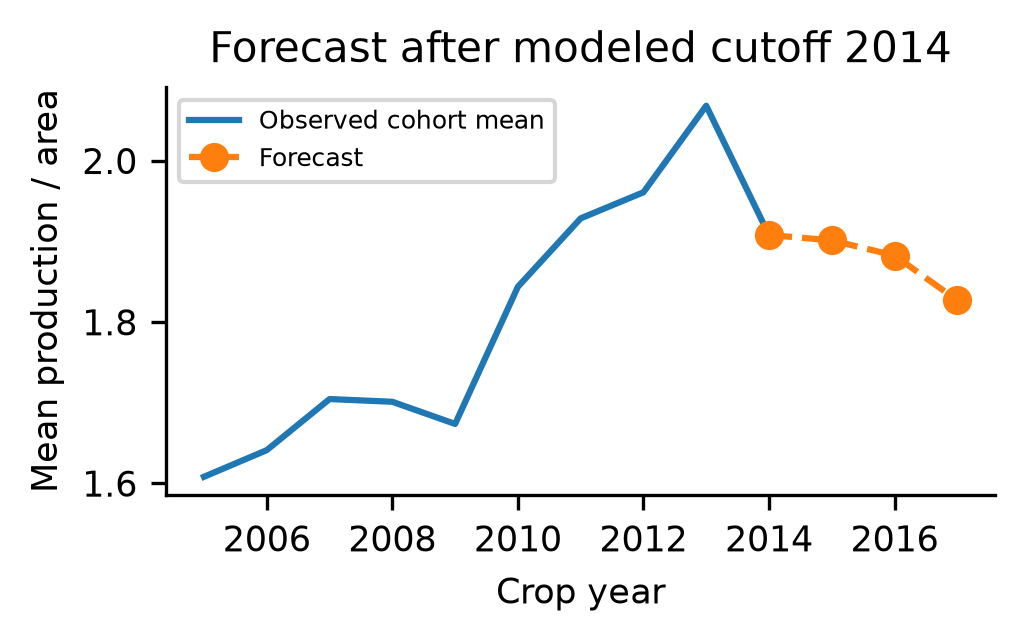

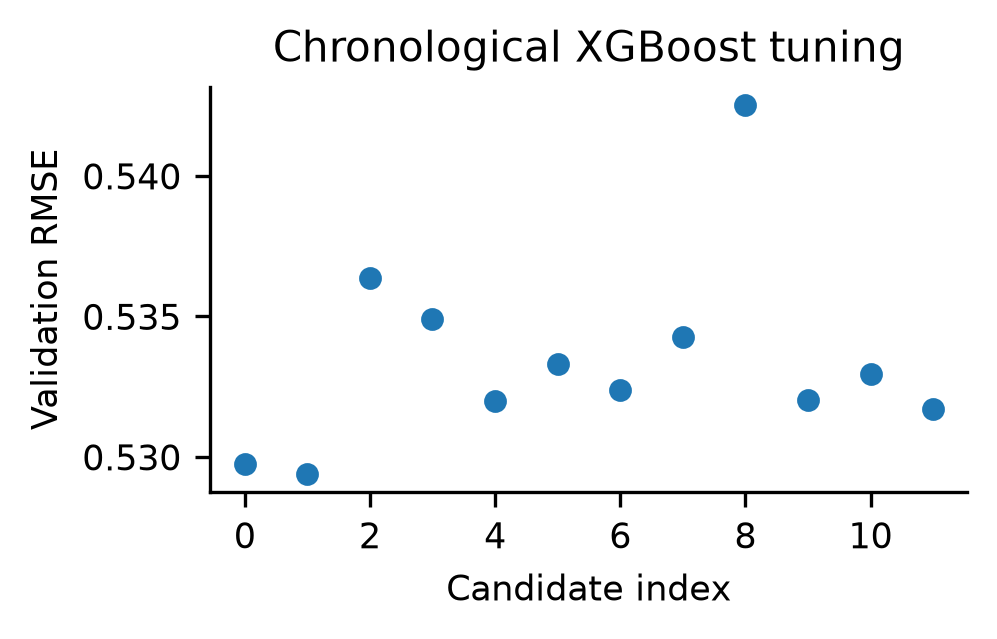

In [13]:
# Audits, errors and real plots.
training=pd.DataFrame(training_records);training.to_csv(ROOT/'training_and_inference.csv',index=False);pd.DataFrame(fitlog).to_csv(ROOT/'fitted_parameters.csv',index=False);pd.DataFrame(failures,columns=['model','sid','origin','mode','error']).to_csv(ROOT/'failed_fits.csv',index=False);pd.DataFrame(timings).to_csv(ROOT/'baseline_runtime.csv',index=False)
for pred,stem in [(test,'one_step'),(fixed,'fixed_origin')]:
 e=pred.merge(metadata.reset_index(),on='sid');e['absolute_error']=abs(e.actual-e.prediction)
 for col in ['Crop','State_Name','year','horizon']:e.groupby(['model',col]).absolute_error.agg(['mean','count']).to_csv(ROOT/f'{stem}_error_by_{col}.csv')
for kind in inner_epochs:
 losses=pd.read_csv(ROOT/(kind+'_loss.csv'));fig,ax=plt.subplots(figsize=(3.5,2.2));ax.plot(losses.epoch,losses.train_normalized_MSE,label='Training through 2008');ax.plot(losses.epoch,losses.validation_normalized_MSE,label='Inner stop year 2009');ax.set(xlabel='Epoch',ylabel='Normalized MSE',title=kind+' actual training loss');ax.legend(fontsize=6);save(kind+'_loss')
fig,ax=plt.subplots(figsize=(3.5,3));tl.set_index('model').RMSE.sort_values().plot.barh(ax=ax);ax.set(xlabel='RMSE (production / area)',title='Expanded one-step test RMSE');save('expanded_comparison')
selected=test[test.model.eq(best)].copy();selected['residual']=selected.actual-selected.prediction
fig,ax=plt.subplots(figsize=(3.5,2.2));selected.groupby('year')[['actual','prediction']].mean().plot(ax=ax,marker='o');ax.set(xlabel='Crop year',ylabel='Mean production / area',title='Validation-selected model: one-step test');save('expanded_actual_predicted')
fig,ax=plt.subplots(figsize=(3.5,2.2));wide.mean(axis=0).plot(ax=ax,label='Observed cohort mean');f=future.groupby('year').forecast_yield_ratio.mean();ax.plot([2014]+list(f.index),[wide[2014].mean()]+list(f),'--o',label='Forecast');ax.set(xlabel='Crop year',ylabel='Mean production / area',title='Forecast after modeled cutoff 2014');ax.legend(fontsize=6);save('expanded_future')
fig,ax=plt.subplots(figsize=(3.5,2.2));trials[trials.status.eq('completed')].plot.scatter(x='trial',y='RMSE',ax=ax);ax.set(xlabel='Candidate index',ylabel='Validation RMSE',title='Chronological XGBoost tuning');save('xgboost_tuning')


## 14 Volatility and multivariate applicability

In [14]:
# ARCH applicability evidence: representative longer history remains very short for volatility estimation.
from statsmodels.stats.diagnostic import acorr_ljungbox,het_arch
rep=long.index[0];_,_,res=fit('AR1_OLS',long.loc[rep].values)
try:
 lb=acorr_ljungbox(res,lags=[1,2],return_df=True);arch=het_arch(res,nlags=1);js('applicability_diagnostics.json',{'representative_sid':rep,'residual_n':len(res),'ARCH_LM_p':arch[1],'Ljung_Box':lb.to_dict(),'GARCH_VAR_exclusion':'14 annual representative residuals and no validated stationary multivariate design; diagnostic is exploratory and not panel-wide evidence'})
except Exception as e:js('applicability_diagnostics.json',{'error':str(e)})


C:\Users\mayan\Documents\Codex\2026-11-18\als\work\pydeps\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


## 15 Integrity tests and execution evidence

In [15]:
# Integrity tests on actual objects and independently reloaded predictions.
assert len(wide)==1112 and wide.shape[1]==10 and not panel.duplicated(key).any();assert np.allclose(panel.y,panel.production/panel.area)
assert set(val.year)=={2010,2011} and set(test.year)=={2012,2013,2014};assert len(future)==3*len(wide)
r=wide.iloc[0];saved=feat(r.loc[:2009],2010);changed=r.copy();changed.loc[2010:]=999999;assert np.allclose(saved,feat(changed.loc[:2009],2010))
read=pd.read_csv(ROOT/'test_predictions.csv');computed=score(read,len(wide)*3).set_index('model');assert np.allclose(computed.loc[tl.model,'RMSE'],tl.RMSE)
js('best_model_summary.json',{'best_by_validation_RMSE':best,'validation':vl[vl.model.eq(best)].to_dict('records'),'test_one_step':tl[tl.model.eq(best)].to_dict('records'),'fixed_origin_three_step':fl[fl.model.eq(best)].to_dict('records'),'test_lowest_RMSE':tl.iloc[0].model,'test_lowest_MAE':tl.sort_values('MAE').iloc[0].model,'test_lowest_MAPE':tl.sort_values('MAPE').iloc[0].model,'evaluated_models':list(tl.model),'failed_fits':len(failures),'optimizer_non_success':int((pd.DataFrame(fitlog).get('optimizer_success',pd.Series(dtype=bool))==False).sum()),'negative_test_predictions':int(test.prediction.lt(0).sum()),'negative_future_predictions':int(future.forecast_yield_ratio.lt(0).sum()),'runtime_seconds':time.perf_counter()-T0})
model_status['XGBoost_Tuned']={'status':'trained and evaluated','trial_count':12,'parameters':chosen_xgb};model_status['ARIMA']={'status':'excluded: environment block','error':'Windows application-control policy blocks statsmodels state-space _inversions extension; no policy changes attempted'};model_status['SARIMA_seasonal_HW']={'status':'excluded: no justified annual periodicity'};model_status['ARCH_GARCH_VAR']={'status':'not fit; short annual histories and inadequate validated multivariate/volatility design'}
js('model_training_status.json',model_status);js('runtime_environment.json',{'python':platform.python_version(),'platform':platform.platform(),'packages':{n:pkg.version(n) for n in ['numpy','pandas','scipy','statsmodels','scikit-learn','xgboost','matplotlib','torch','prophet']},'seed':42,'device':'CPU','torch_threads':2});js('hyperparameters.json',{'XGBoost_candidates':CANDIDATES,'selected_xgboost':chosen_xgb,'neural_models':{k:v for k,v in model_status.items() if k in inner_epochs},'selection_metric':'outer validation RMSE','test_previously_seen':True})
(ROOT/'test_results.txt').write_text('PASS weighted aggregation identity; unique annual keys; complete panel; chronological target windows; future-target feature invariance; forecast alignment; saved-prediction RMSE recalculation; neural parameter updates; neural checkpoint inference replay.\nProphet is evaluated separately on different aggregate targets. Colab hosted execution not certified by this local run.\n')
print('FINAL EXTENSION FINISHED',round(time.perf_counter()-T0,2),'seconds',flush=True)


FINAL EXTENSION FINISHED 140.96 seconds


## 16 Additional EDA and diagnostic exports
State and national series remain separated by crop. Numerical correlations and outlier flags are descriptive. No outliers are removed merely because they exceed an IQR threshold. Centered rolling trend views are never forecasting inputs.

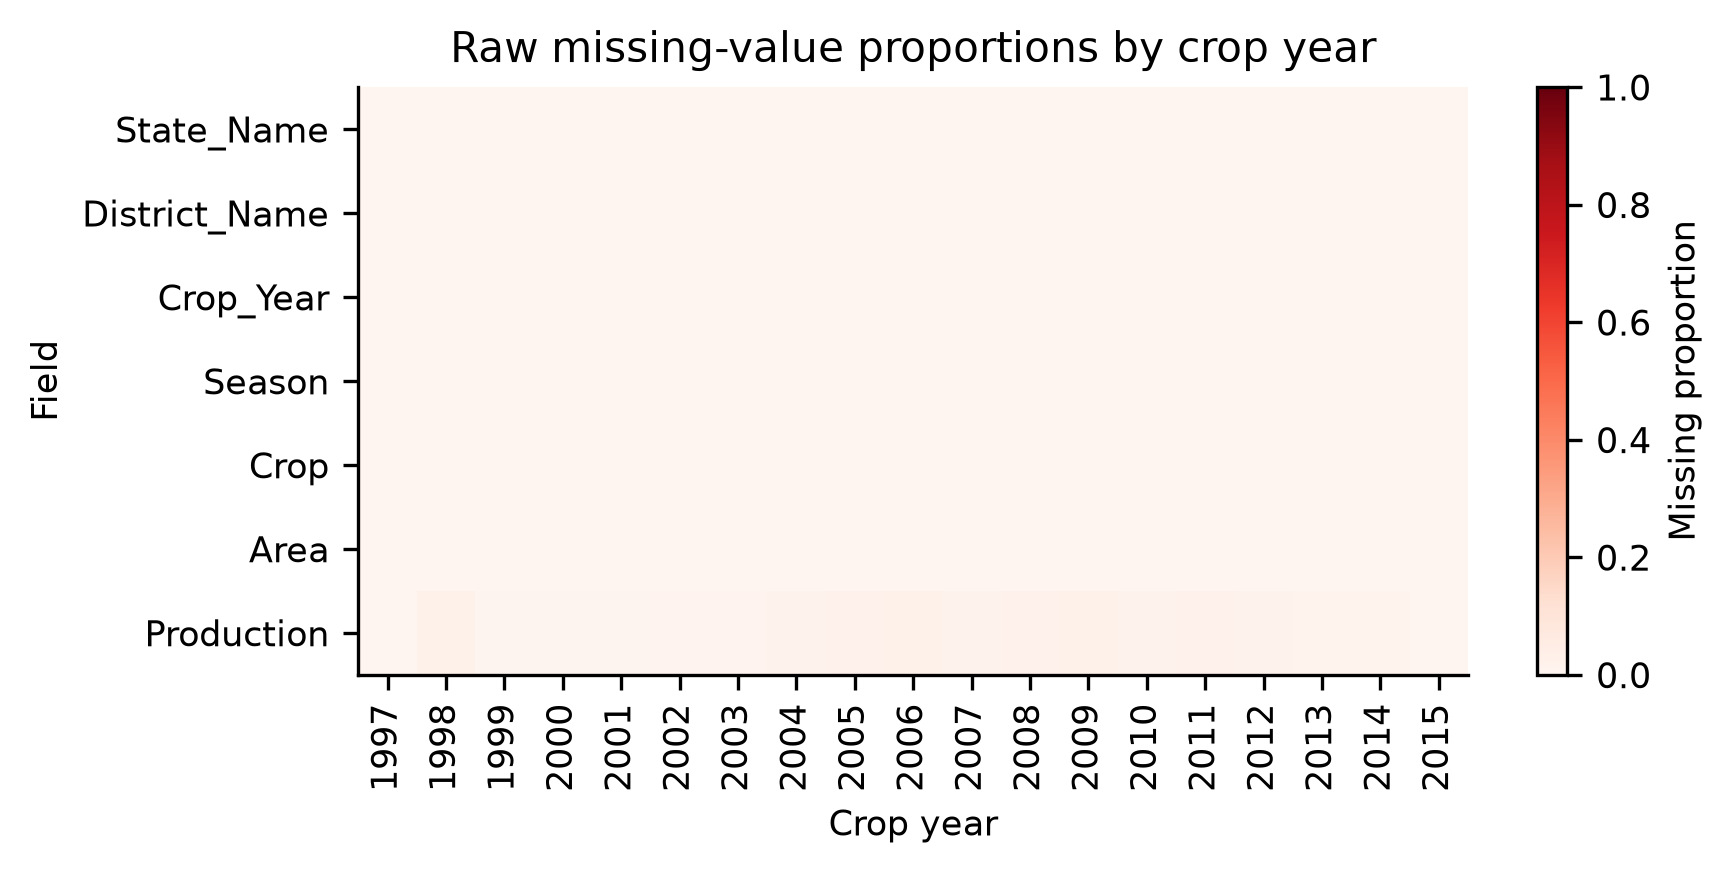

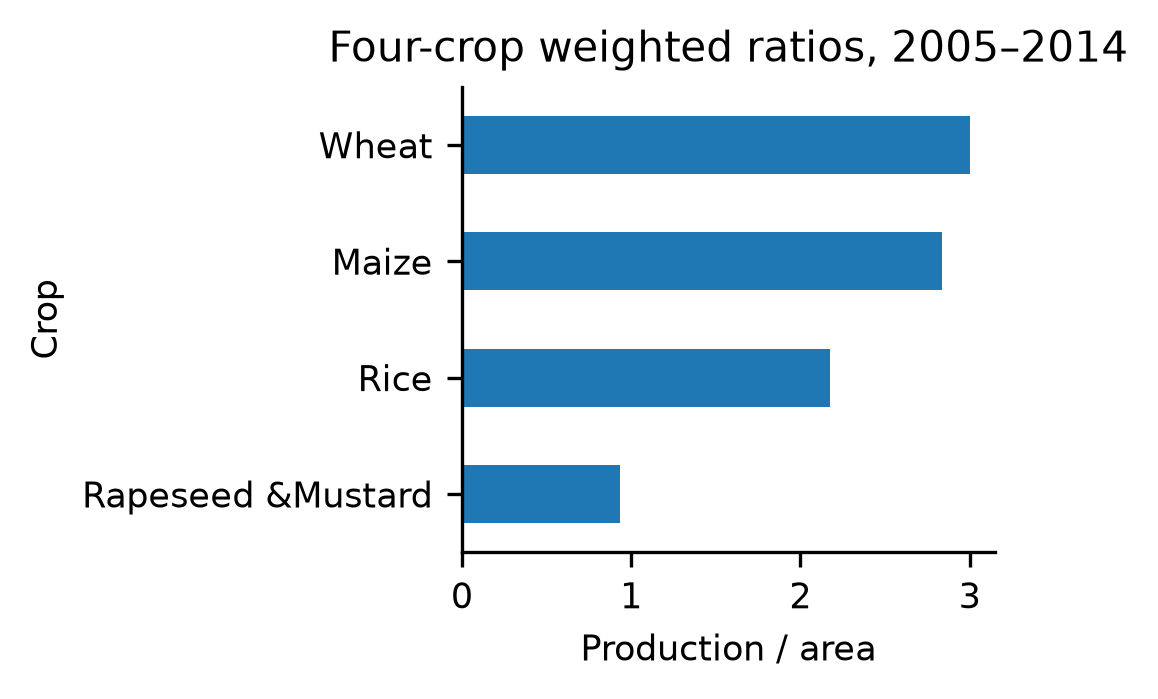

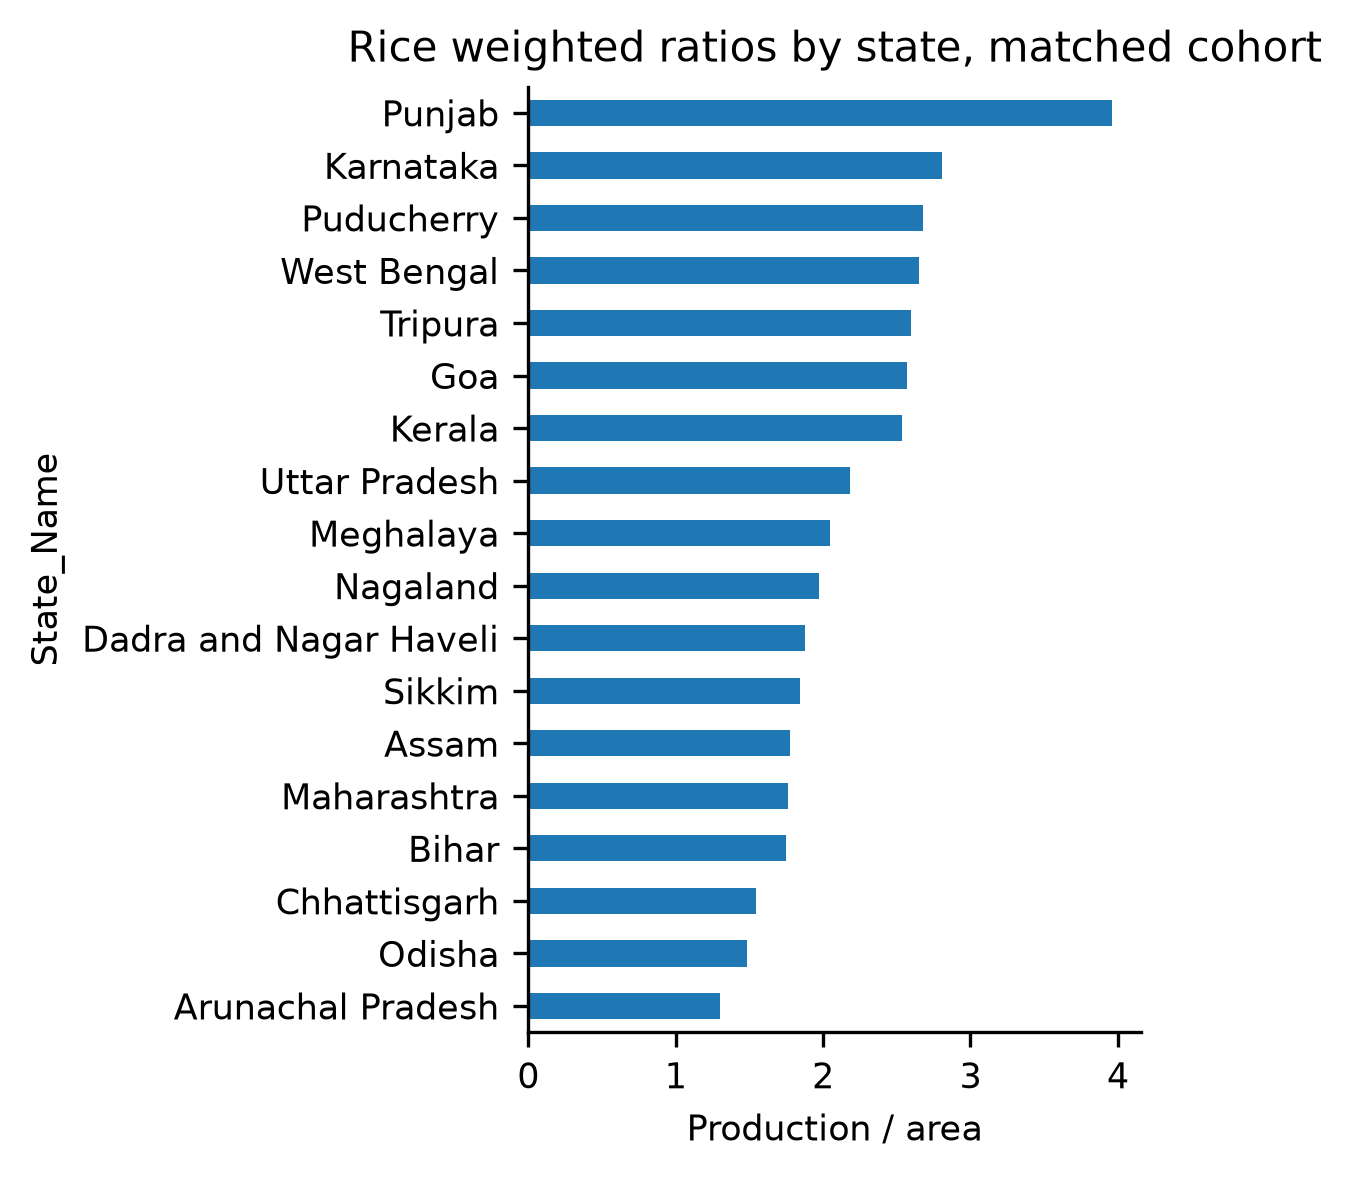

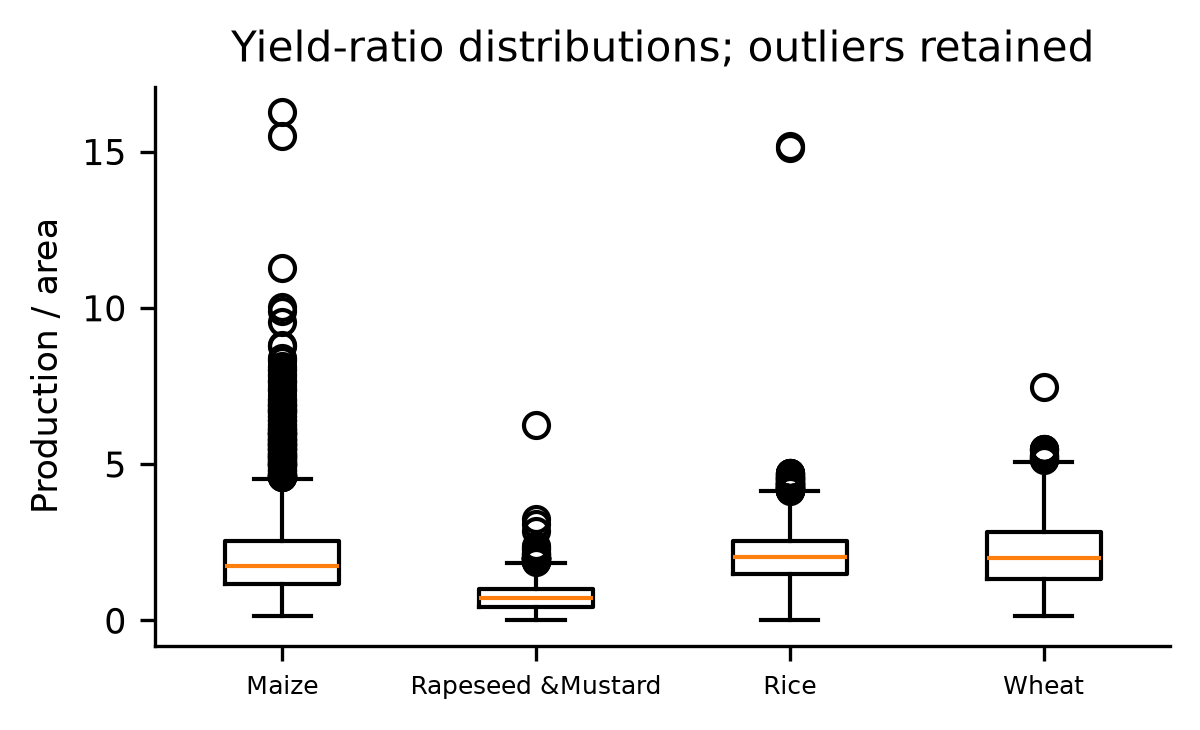

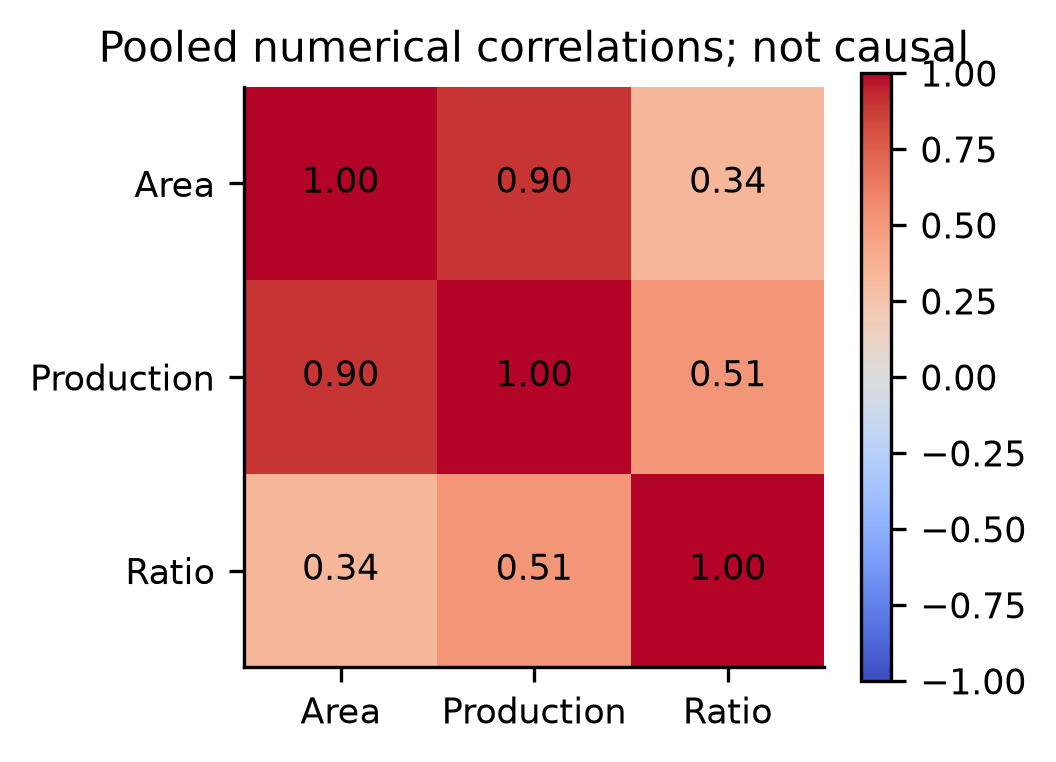

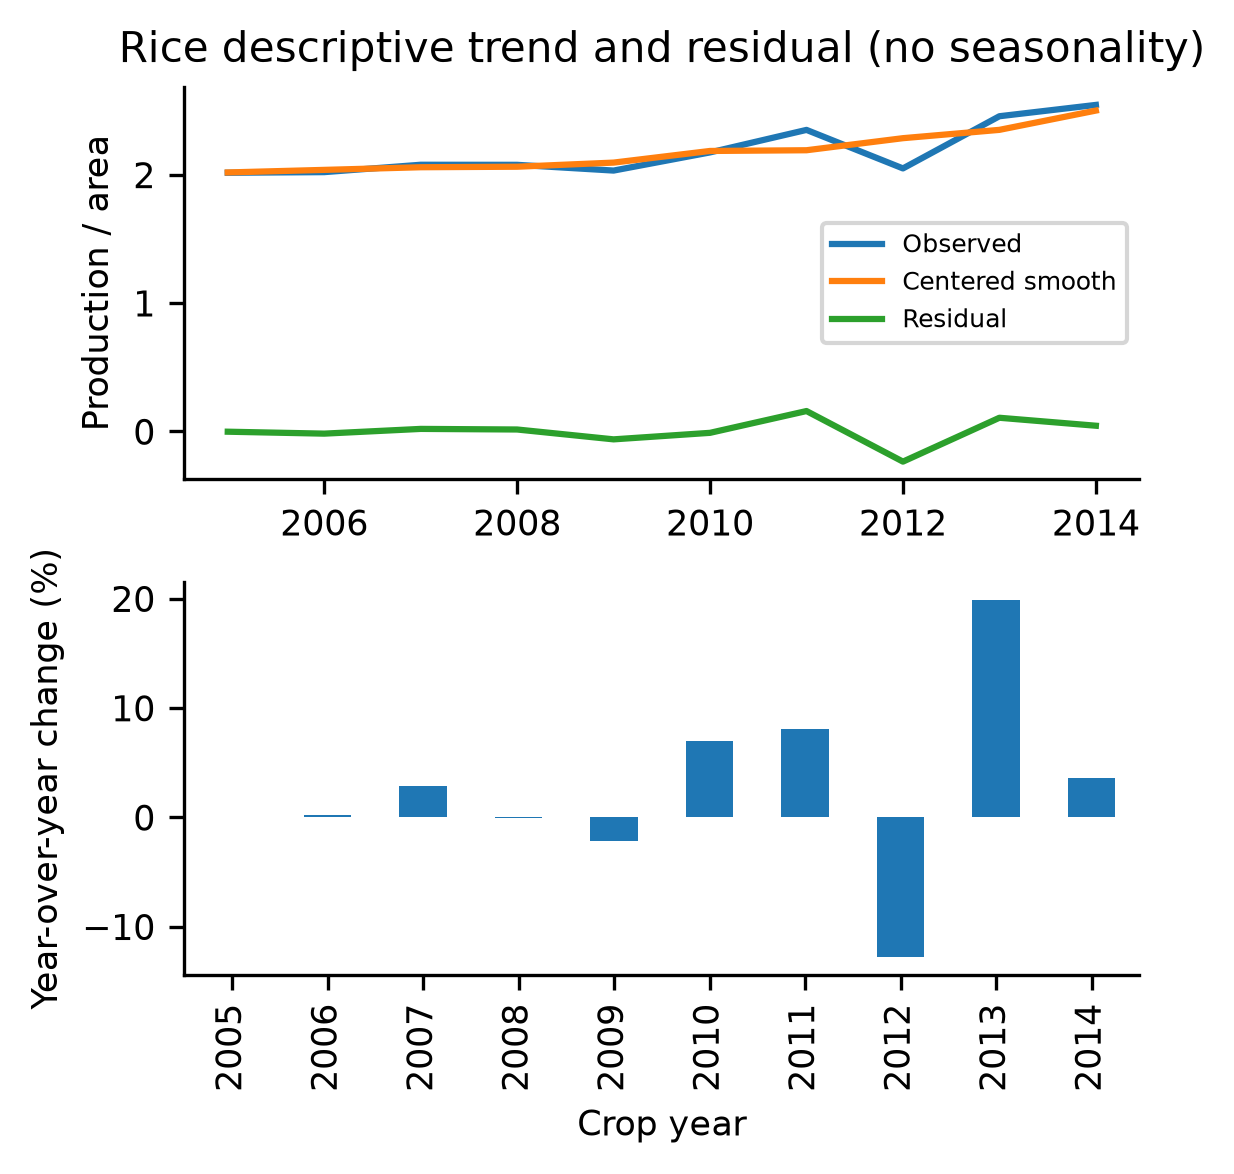

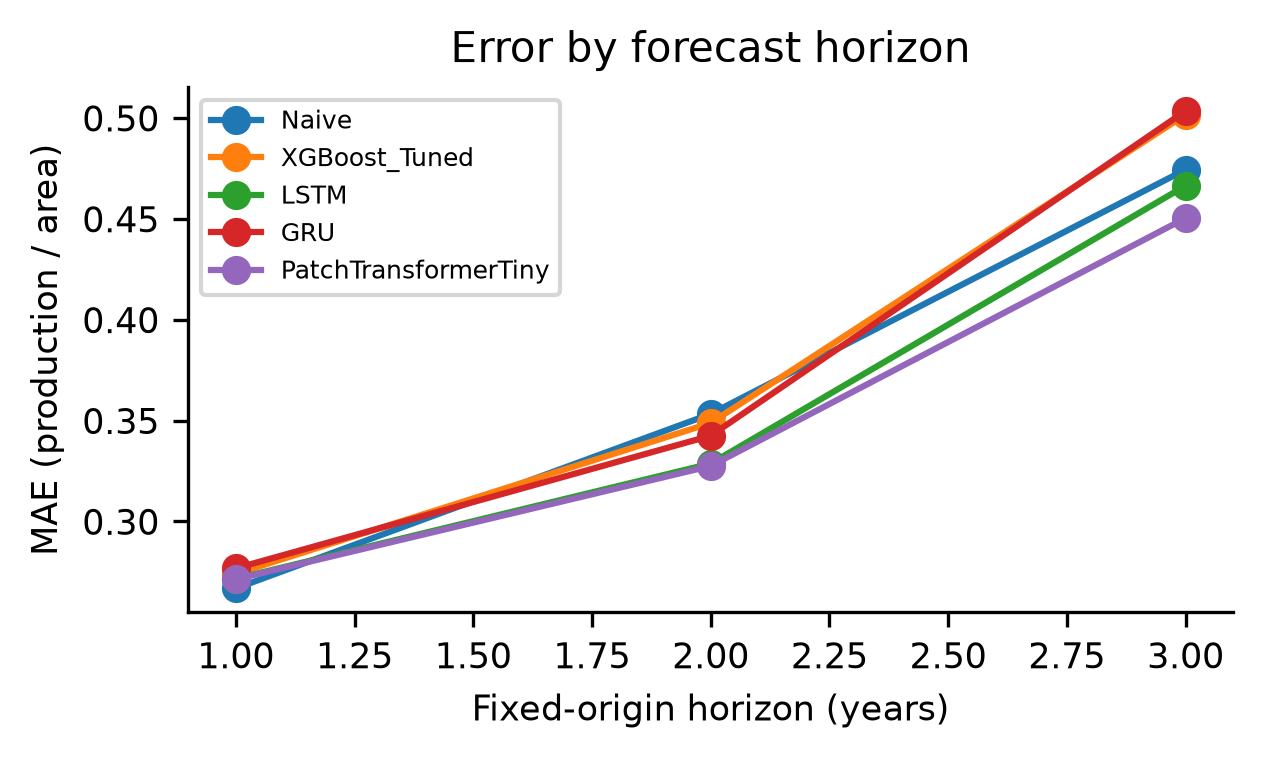

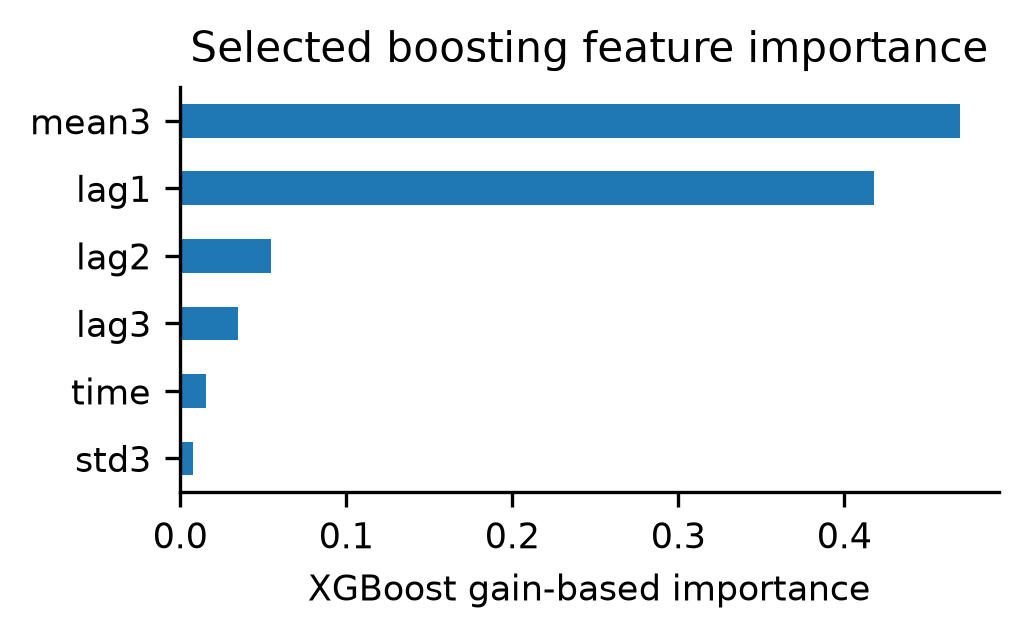

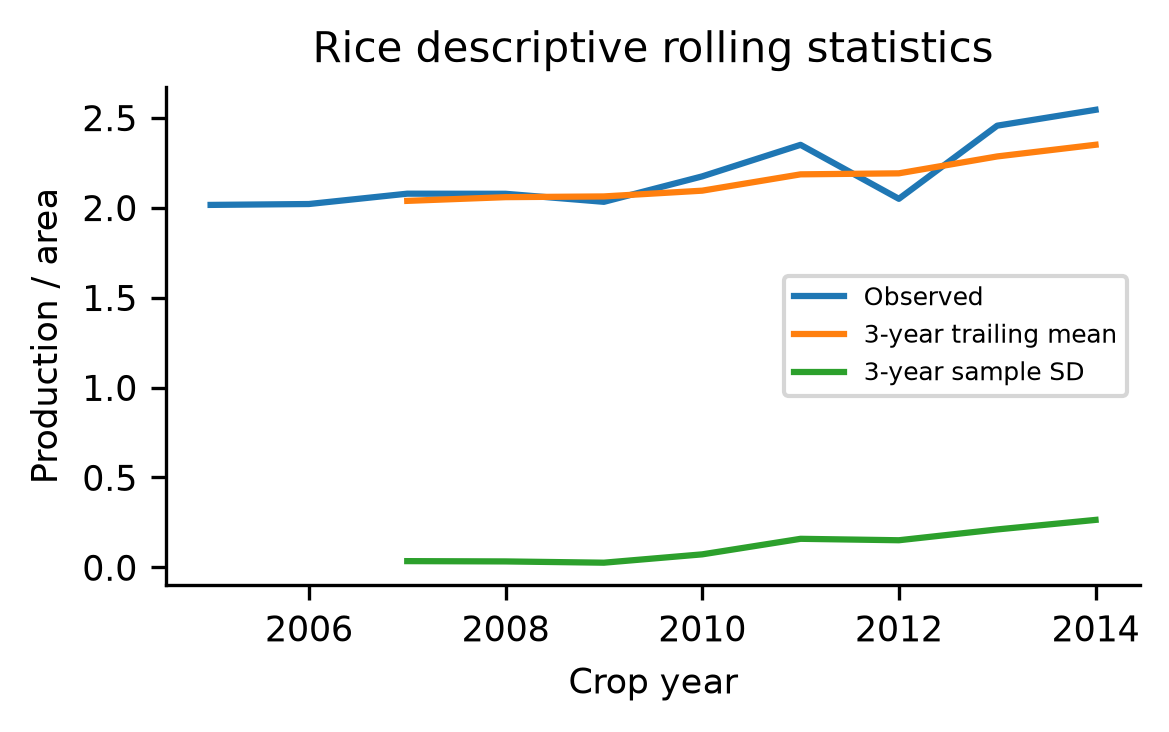

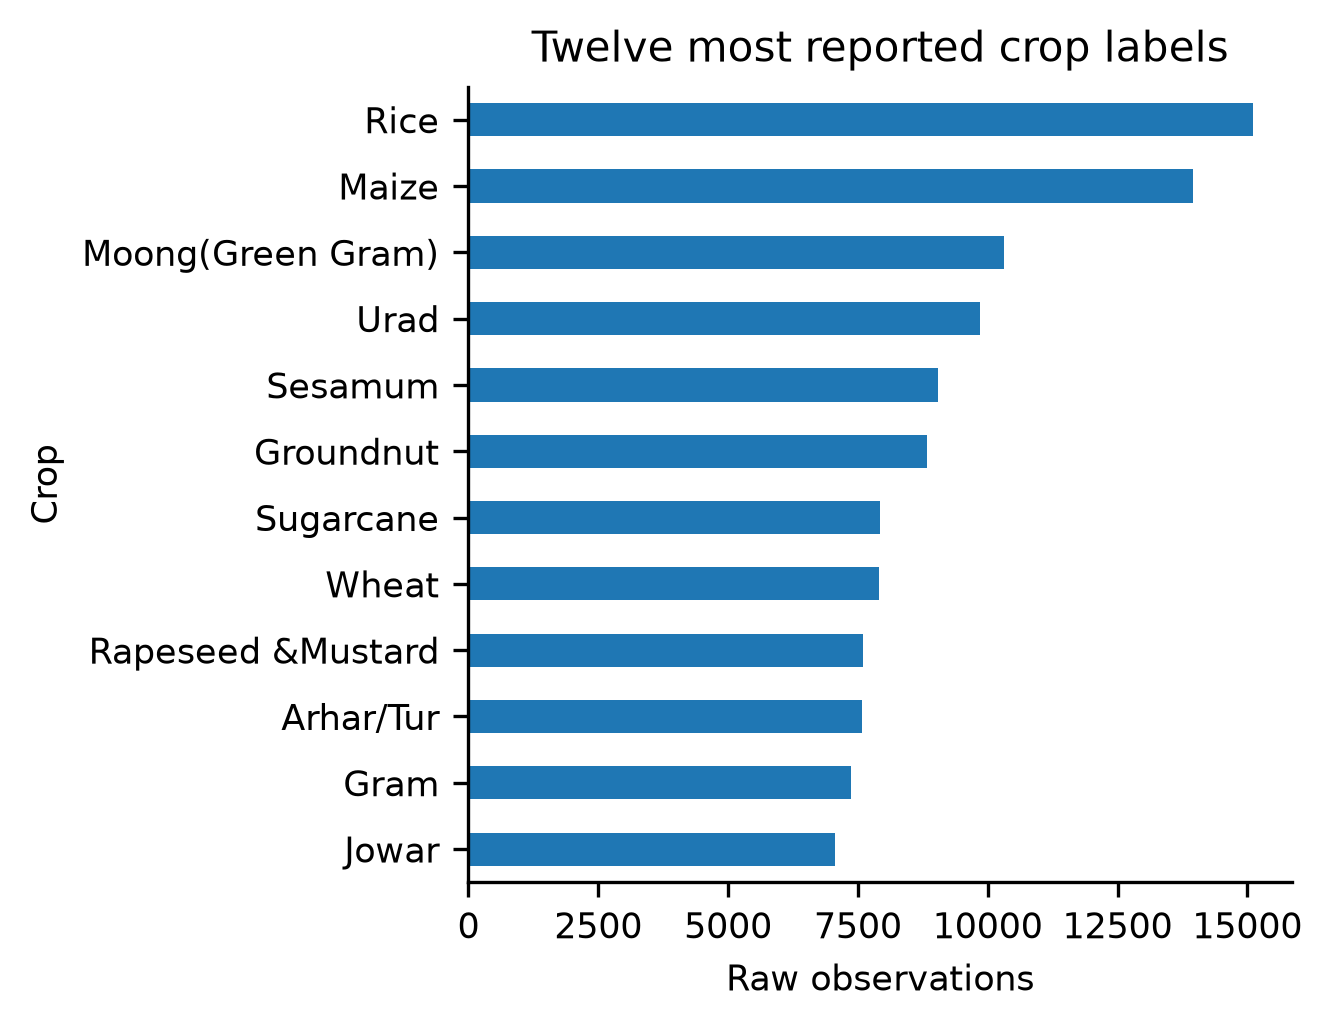

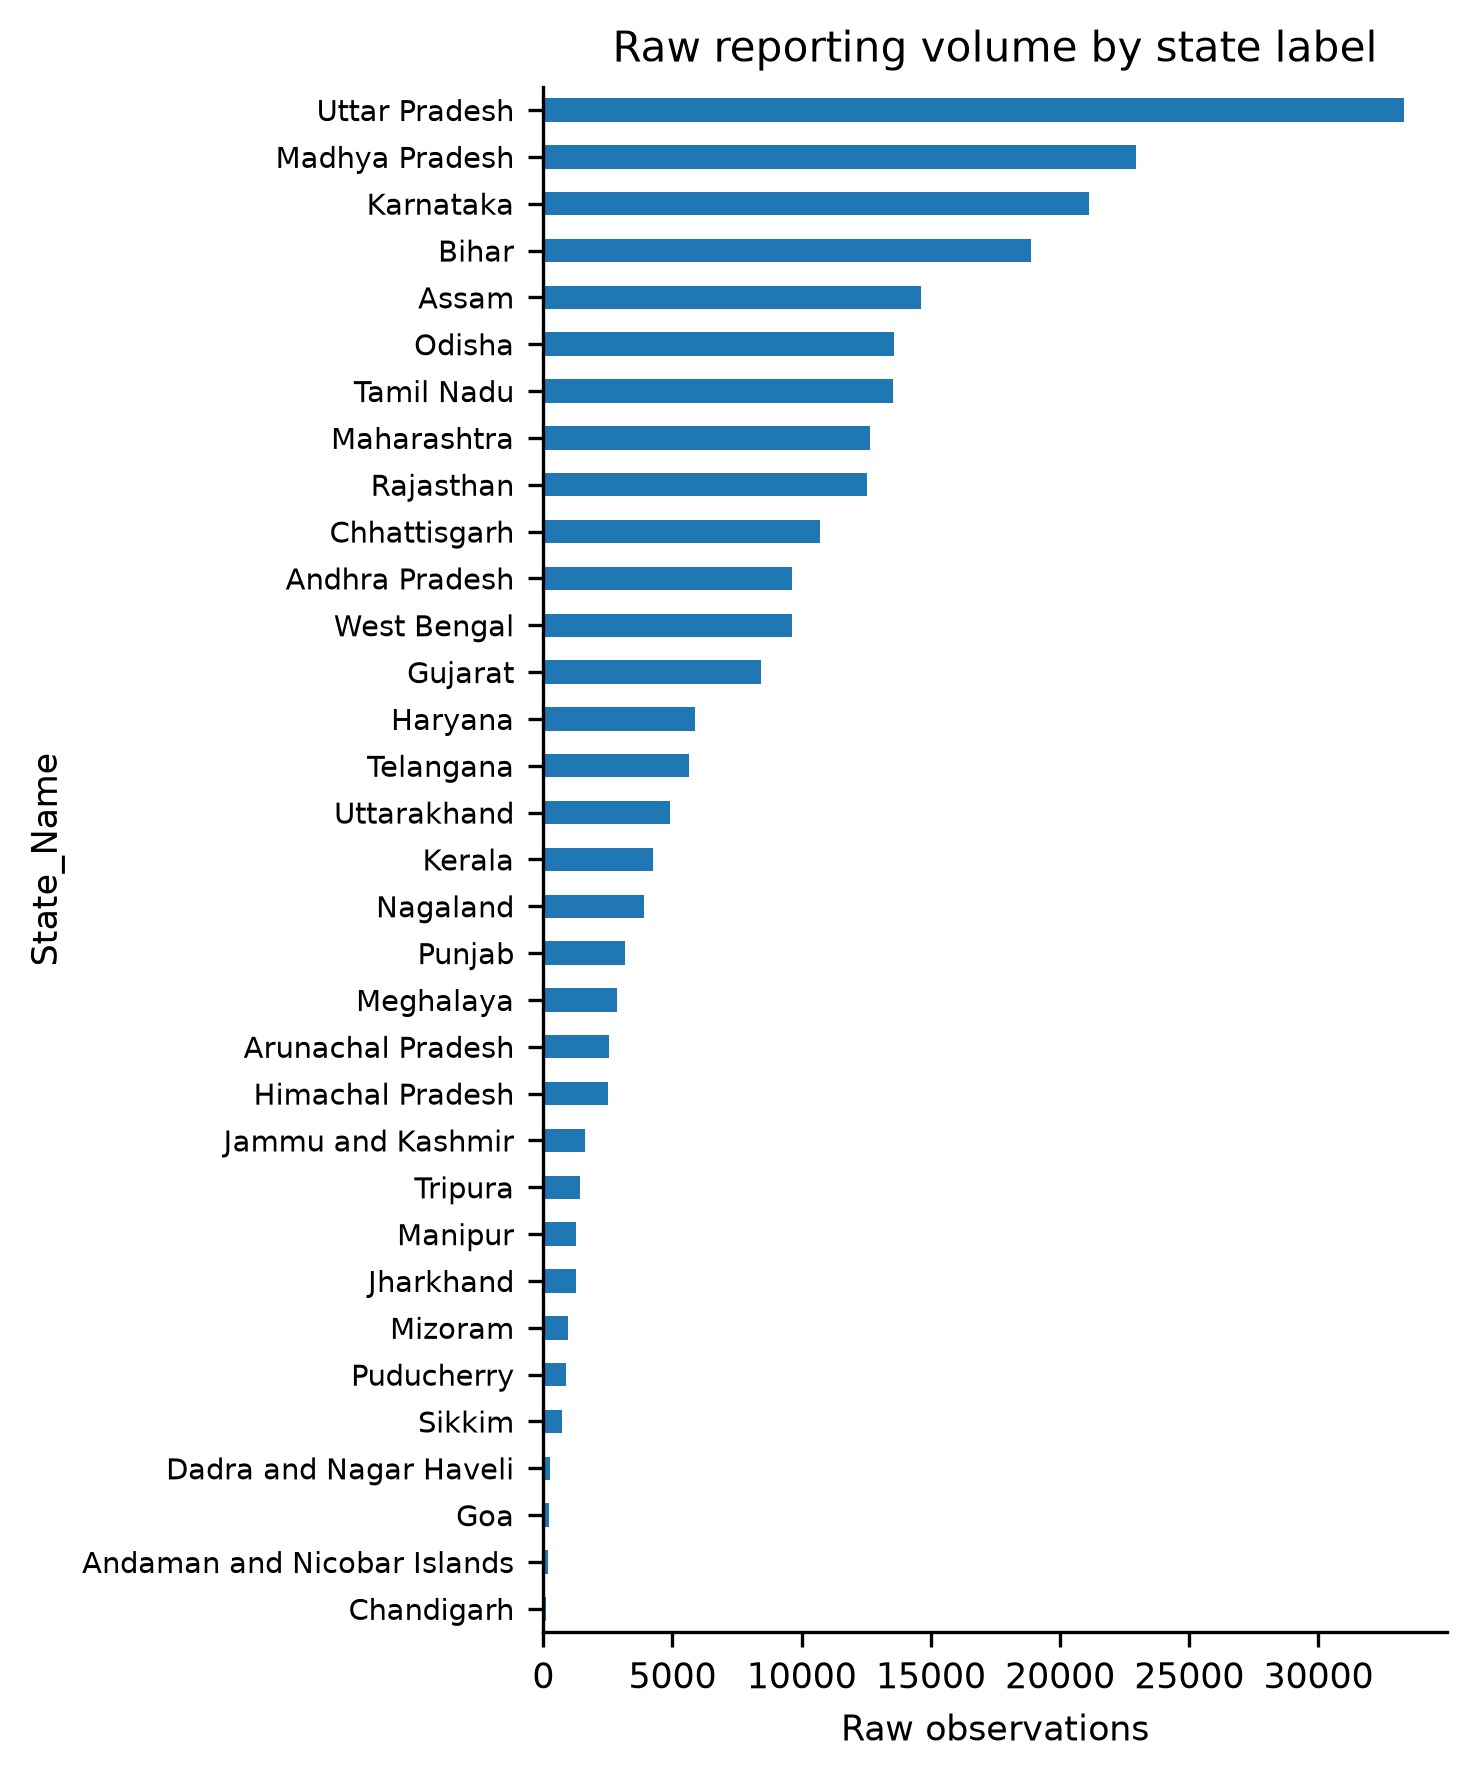

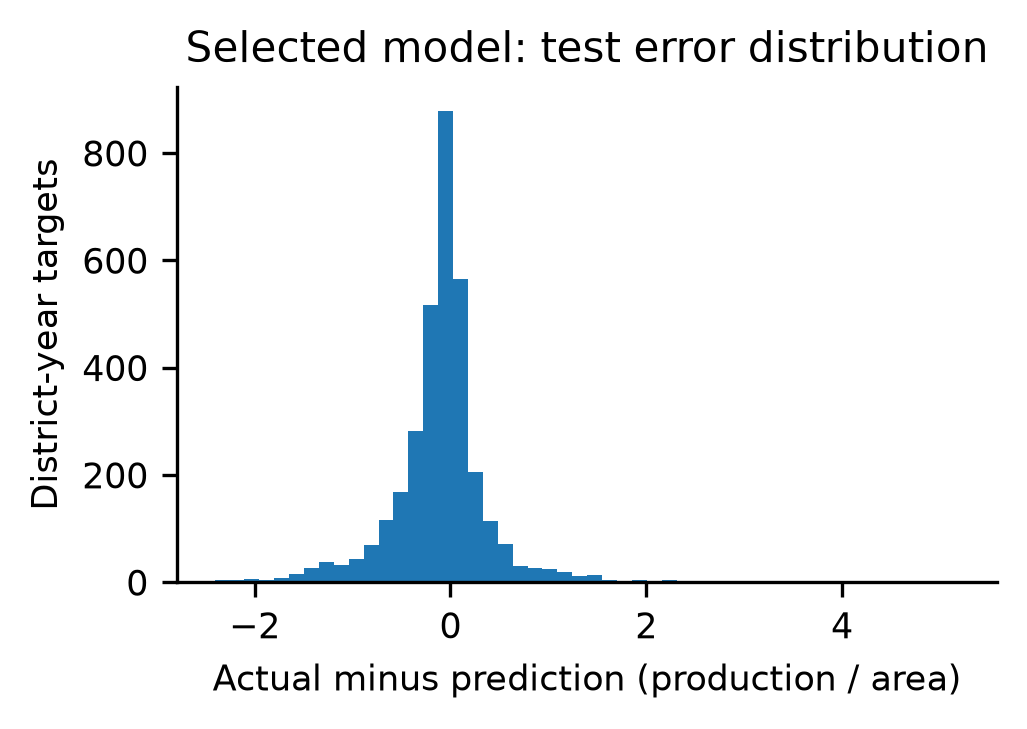

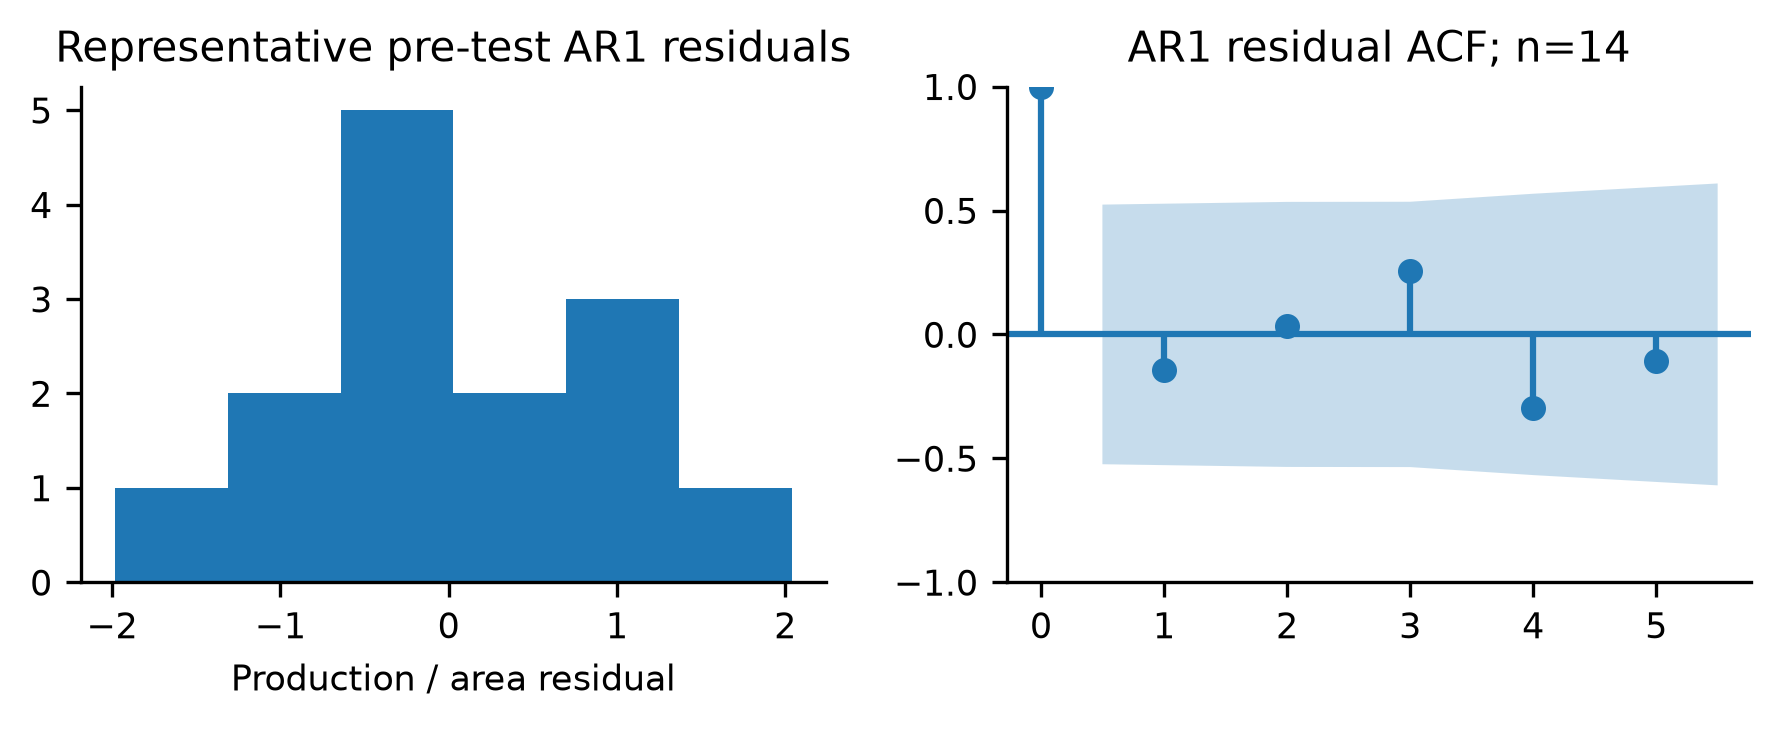

Additional EDA generated; no forecast or model-selection values changed.


In [16]:
"""Additional descriptive EDA, generated only from exported observations."""
from pathlib import Path
import json,os
import numpy as np,pandas as pd
import matplotlib;matplotlib.use('Agg')
import matplotlib.pyplot as plt

def additional_eda(root):
 root=Path(root);figdir=root/'figures';panel=pd.read_csv(root/'annual_panel.csv');raw=pd.read_csv(os.environ.get('APY_CSV','raw/crop_production.csv'));selected=pd.read_csv(root/'selected_series.csv');ids=set(selected.sid);subset=panel[panel.sid.isin(ids)&panel.Crop_Year.between(2005,2014)]
 def save(name):
  plt.tight_layout();p=figdir/(name+'.png');plt.savefig(p,dpi=300,bbox_inches='tight');plt.close()
  try:
   from IPython.display import display,Image
   display(Image(filename=str(p)))
  except ImportError:print('Saved',p.name)
 # National and state totals remain separated by crop; mixed commodity unit sums are avoided.
 for label,keys in [('state_crop',['State_Name','Crop','Crop_Year']),('national_crop',['Crop','Crop_Year'])]:
  a=panel.groupby(keys)[['area','production']].sum().reset_index();a['yield_ratio']=a.production/a.area;a.to_csv(root/(label+'_annual_series.csv'),index=False)
 miss=raw.isna().groupby(raw.Crop_Year).mean();fig,ax=plt.subplots(figsize=(6,3));im=ax.imshow(miss.T.values,aspect='auto',vmin=0,vmax=1,cmap='Reds');ax.set_xticks(range(len(miss)),miss.index,rotation=90);ax.set_yticks(range(len(miss.columns)),miss.columns);ax.set(title='Raw missing-value proportions by crop year',xlabel='Crop year',ylabel='Field');fig.colorbar(im,ax=ax,label='Missing proportion');save('missing_heatmap')
 fig,ax=plt.subplots(figsize=(3.5,2.4));subset.groupby('Crop').apply(lambda g:g.production.sum()/g.area.sum(),include_groups=False).sort_values().plot.barh(ax=ax);ax.set(xlabel='Production / area',title='Four-crop weighted ratios, 2005–2014');save('crop_comparison')
 rice=subset[subset.Crop.eq('Rice')];state=rice.groupby('State_Name')[['area','production']].sum();state['ratio']=state.production/state.area;state.to_csv(root/'rice_state_comparison.csv');fig,ax=plt.subplots(figsize=(4,4));state.ratio.sort_values().plot.barh(ax=ax);ax.set(xlabel='Production / area',title='Rice weighted ratios by state, matched cohort');save('state_comparison')
 fig,ax=plt.subplots(figsize=(4.2,2.5));groups=[g.y.values for _,g in subset.groupby('Crop')];labels=[c for c,_ in subset.groupby('Crop')];ax.boxplot(groups,tick_labels=labels,showfliers=True);ax.tick_params(axis='x',labelsize=6);ax.set(ylabel='Production / area',title='Yield-ratio distributions; outliers retained');save('yield_distributions')
 corr=subset[['area','production','y']].corr();corr.to_csv(root/'descriptive_correlations.csv');fig,ax=plt.subplots(figsize=(3.5,2.7));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(3),['Area','Production','Ratio']);ax.set_yticks(range(3),['Area','Production','Ratio']);ax.set_title('Pooled numerical correlations; not causal')
 for i in range(3):
  for j in range(3):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
 fig.colorbar(im,ax=ax);save('correlation_heatmap')
 crop=pd.read_csv(root/'weighted_crop_series.csv');y=crop[crop.Crop.eq('Rice')].set_index('Crop_Year').yield_ratio;trend=y.rolling(3,center=True,min_periods=2).mean();changes=y.pct_change(fill_method=None)*100
 pd.DataFrame({'observed':y,'centered_3yr_smooth':trend,'residual':y-trend,'year_over_year_pct':changes}).to_csv(root/'rice_descriptive_components.csv')
 fig,axes=plt.subplots(2,1,figsize=(4,4));axes[0].plot(y.index,y,label='Observed');axes[0].plot(trend.index,trend,label='Centered smooth');axes[0].plot(y.index,y-trend,label='Residual');axes[0].legend(fontsize=6);axes[0].set(ylabel='Production / area',title='Rice descriptive trend and residual (no seasonality)');changes.plot.bar(ax=axes[1]);axes[1].set(ylabel='Year-over-year change (%)',xlabel='Crop year');save('trend_residual_growth')
 out=[]
 for crop,g in subset.groupby('Crop'):
  q1,q3=g.y.quantile([.25,.75]);iqr=q3-q1;out.append({'crop':crop,'q1':q1,'q3':q3,'IQR':iqr,'flagged':int(((g.y<q1-1.5*iqr)|(g.y>q3+1.5*iqr)).sum()),'retained_rows':len(g)})
 pd.DataFrame(out).to_csv(root/'outlier_audit.csv',index=False)
 horizon=pd.read_csv(root/'fixed_origin_error_by_horizon.csv');fig,ax=plt.subplots(figsize=(4.3,2.6))
 for name in ['Naive','XGBoost_Tuned','LSTM','GRU','PatchTransformerTiny']:
  a=horizon[horizon.model.eq(name)];ax.plot(a.horizon,a['mean'],marker='o',label=name)
 ax.set(xlabel='Fixed-origin horizon (years)',ylabel='MAE (production / area)',title='Error by forecast horizon');ax.legend(fontsize=6);save('horizon_errors')
 fi=root/'feature_importance.csv'
 if fi.exists():
  a=pd.read_csv(fi,index_col=0).iloc[:,0];fig,ax=plt.subplots(figsize=(3.5,2.2));a.sort_values().plot.barh(ax=ax);ax.set(xlabel='XGBoost gain-based importance',title='Selected boosting feature importance');save('feature_importance')
 desc={c:{'dtype':str(raw[c].dtype),'missing':int(raw[c].isna().sum())} for c in raw};(root/'feature_descriptions.json').write_text(json.dumps(desc,indent=2))
 # Explicit rolling SD, raw distributions and residual diagnostics required for the EDA audit.
 fig,ax=plt.subplots(figsize=(4,2.5));ax.plot(y.index,y,label='Observed');ax.plot(y.index,y.rolling(3).mean(),label='3-year trailing mean');ax.plot(y.index,y.rolling(3).std(),label='3-year sample SD');ax.set(xlabel='Crop year',ylabel='Production / area',title='Rice descriptive rolling statistics');ax.legend(fontsize=6);save('rolling_mean_std')
 pd.DataFrame({'observed':y,'rolling_mean_3':y.rolling(3).mean(),'rolling_sample_std_3':y.rolling(3).std()}).to_csv(root/'rice_rolling_statistics.csv')
 cc=raw.Crop.str.strip().value_counts();cc.to_csv(root/'raw_crop_counts.csv');fig,ax=plt.subplots(figsize=(4.5,3.5));cc.head(12).sort_values().plot.barh(ax=ax);ax.set(xlabel='Raw observations',title='Twelve most reported crop labels');save('raw_crop_distribution')
 sc=raw.State_Name.str.strip().value_counts();sc.to_csv(root/'raw_state_counts.csv');fig,ax=plt.subplots(figsize=(5,6));sc.sort_values().plot.barh(ax=ax);ax.set(xlabel='Raw observations',title='Raw reporting volume by state label');ax.tick_params(axis='y',labelsize=7);save('raw_state_distribution')
 summary=json.loads((root/'best_model_summary.json').read_text());chosen=summary['best_by_validation_RMSE'];pred=pd.read_csv(root/'test_predictions.csv');sel=pred[pred.model.eq(chosen)].copy();sel['error']=sel.actual-sel.prediction;fig,ax=plt.subplots(figsize=(3.5,2.5));ax.hist(sel.error,bins=50);ax.set(xlabel='Actual minus prediction (production / area)',ylabel='District-year targets',title='Selected model: test error distribution');save('selected_test_residual_distribution')
 diagnostic=json.loads((root/'applicability_diagnostics.json').read_text());sid=diagnostic.get('representative_sid')
 if sid is not None:
  from statsmodels.graphics.tsaplots import plot_acf
  hist=panel[(panel.sid==sid)&panel.Crop_Year.between(1997,2011)].sort_values('Crop_Year');vals=hist.y.to_numpy();xx=np.column_stack([np.ones(len(vals)-1),vals[:-1]]);coef=np.linalg.lstsq(xx,vals[1:],rcond=None)[0];res=vals[1:]-xx@coef;pd.DataFrame({'year':hist.Crop_Year.values[1:],'residual':res}).to_csv(root/'representative_AR1_training_residuals.csv',index=False)
  fig,axes=plt.subplots(1,2,figsize=(6,2.5));axes[0].hist(res,bins=6);axes[0].set(xlabel='Production / area residual',title='Representative pre-test AR1 residuals');plot_acf(res,lags=5,ax=axes[1]);axes[1].set_title('AR1 residual ACF; n=14');save('representative_AR1_residual_diagnostics')
 print('Additional EDA generated; no forecast or model-selection values changed.')

additional_eda(ROOT)


## 17 Results to show during teacher evaluation
The validation-selected model and retrospective test winner answer different questions. A successful notebook execution can still contain an explicitly excluded model; read the status table and logs.

In [17]:
from IPython.display import display
print('Validation selection:',best)
display(vl[['model','MAE','RMSE','MAPE']])
print('Expanding one-step test:');display(tl[['model','MAE','RMSE','MAPE','RMSE_improvement_vs_naive_pct']])
print('Fixed-origin three-step test:');display(fl[['model','MAE','RMSE','MAPE']])
print('Model execution statuses:');display(pd.DataFrame(model_status).T)
print('Future forecast sample:');display(future.head(12))


Validation selection: XGBoost_Tuned


,model,MAE,RMSE,MAPE
11,XGBoost_Tuned,0.275527,0.529400,17.914181
5,LSTM,0.276755,0.533001,19.312809
3,GRU,0.282133,0.538972,20.262791
6,MA3,0.281548,0.540397,16.376749
7,Mean,0.307892,0.546750,17.473946
9,PatchTransformerTiny,0.279884,0.548783,18.795653
10,SES_LS,0.294346,0.635824,17.191219
8,Naive,0.296548,0.648530,17.749727
2,Drift,0.325834,0.724308,20.242465
1,DampedHolt_LS,0.324379,0.764947,19.674661


Expanding one-step test:


,model,MAE,RMSE,MAPE,RMSE_improvement_vs_naive_pct
0,LSTM,0.326498,0.545658,23.561181,3.941651
1,PatchTransformerTiny,0.325342,0.549615,22.665306,3.245089
2,GRU,0.332123,0.551099,25.163281,2.983768
3,XGBoost_Tuned,0.336924,0.561743,24.765871,1.109914
4,Naive,0.329783,0.568048,20.656878,0.000000
5,SES_LS,0.342786,0.574474,21.166036,-1.131109
6,MA3,0.339886,0.579556,20.885357,-2.025811
7,Drift,0.362899,0.616296,22.698866,-8.493520
8,Mean,0.407221,0.634924,23.512636,-11.772888
9,DampedHolt_LS,0.369102,0.659145,22.910926,-16.036765


Fixed-origin three-step test:


,model,MAE,RMSE,MAPE
0,LSTM,0.355550,0.599152,24.597346
1,PatchTransformerTiny,0.349721,0.600379,22.797720
2,GRU,0.374230,0.600513,30.974900
3,Naive,0.364825,0.619108,22.374096
4,XGBoost_Tuned,0.374807,0.628338,25.814324
5,SES_LS,0.384164,0.634288,22.889710
6,MA3,0.388431,0.636350,23.062519
7,Mean,0.431899,0.669703,24.688844
8,DampedHolt_LS,0.425058,0.739123,25.884070
9,Drift,0.447086,0.760127,27.379885


Model execution statuses:


,status,selected_epochs,parameter_count,lookback,normalization,inner_train_end,inner_stop_year,max_epochs,patience,dropout,learning_rate,batch_size,error,traceback,trial_count,parameters
LSTM,trained and evaluated,49,1233,3,fit separately on each training origin,2008,2009,60,8,0.1,0.003,256,NaN,NaN,NaN,NaN
GRU,trained and evaluated,52,929,3,fit separately on each training origin,2008,2009,60,8,0.1,0.003,256,NaN,NaN,NaN,NaN
PatchTransformerTiny,trained and evaluated,31,657,3,fit separately on each training origin,2008,2009,60,8,0.1,0.003,256,NaN,NaN,NaN,NaN
Prophet,excluded after runtime failure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Error during optimization! Command 'C:\Users\m...,"Traceback (most recent call last):\n File ""C:...",NaN,NaN
XGBoost_Tuned,trained and evaluated,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,"{'n_estimators': 250, 'max_depth': 3, 'learnin..."
ARIMA,excluded: environment block,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Windows application-control policy blocks stat...,NaN,NaN,NaN
SARIMA_seasonal_HW,excluded: no justified annual periodicity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARCH_GARCH_VAR,not fit; short annual histories and inadequate...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Future forecast sample:


,sid,year,horizon,forecast_yield_ratio,model,modeled_cutoff
0,Andhra Pradesh|ANANTAPUR|Maize,2015,1,2.908283,XGBoost_Tuned,2014
1,Andhra Pradesh|CHITTOOR|Maize,2015,1,4.564246,XGBoost_Tuned,2014
2,Andhra Pradesh|EAST GODAVARI|Maize,2015,1,7.361312,XGBoost_Tuned,2014
3,Andhra Pradesh|GUNTUR|Maize,2015,1,7.835023,XGBoost_Tuned,2014
4,Andhra Pradesh|KRISHNA|Maize,2015,1,5.603865,XGBoost_Tuned,2014
5,Andhra Pradesh|KURNOOL|Maize,2015,1,4.778106,XGBoost_Tuned,2014
6,Andhra Pradesh|PRAKASAM|Maize,2015,1,7.657103,XGBoost_Tuned,2014
7,Andhra Pradesh|SRIKAKULAM|Maize,2015,1,4.748229,XGBoost_Tuned,2014
8,Andhra Pradesh|VISAKHAPATANAM|Maize,2015,1,2.385725,XGBoost_Tuned,2014
9,Andhra Pradesh|VIZIANAGARAM|Maize,2015,1,4.441386,XGBoost_Tuned,2014


## 18 Quick live demonstration check
This cell refits only the selected XGBoost configuration at origin 2011 and checks one 2012 prediction against the saved one-step result. It does not tune using that target or change the selected model.

In [18]:
demo_X,demo_y=xy(2011)
live_check_model=XGBRegressor(**chosen_xgb,objective='reg:squarederror',random_state=42,n_jobs=2).fit(demo_X,demo_y)
demo_sid=wide.index[0]
demo_feature=np.array([feat(wide.loc[demo_sid,:2011].values,2012)])
live_value=float(live_check_model.predict(demo_feature)[0])
stored_value=float(test[(test.model=='XGBoost_Tuned')&(test.sid==demo_sid)&(test.year==2012)].prediction.iloc[0])
np.testing.assert_allclose(live_value,stored_value,rtol=1e-7,atol=1e-7)
print('PASS: one-origin refit reproduces saved prediction.')
print('Series:',demo_sid,'Target: 2012','Prediction:',live_value)


PASS: one-origin refit reproduces saved prediction.
Series: Andhra Pradesh|ANANTAPUR|Maize Target: 2012 Prediction: 5.531285285949707


## 19 Dataset identity and download
Save this notebook with outputs after a fresh Colab run. A runtime or environment difference may change numerical results; regenerate the report if results change.

In [19]:
import hashlib,shutil
identity={'name':Path(os.environ['APY_CSV']).name,'bytes':Path(os.environ['APY_CSV']).stat().st_size,'sha256':hashlib.sha256(Path(os.environ['APY_CSV']).read_bytes()).hexdigest()}
js('input_identity.json',identity)
archive=shutil.make_archive(str(ROOT.resolve().parent/'crop_yield_final_evidence'),'zip',ROOT)
print('Completed. Evidence ZIP:',Path(archive).name)
print('Input SHA-256:',identity['sha256'])
if COLAB_MODE:files.download(archive)


Completed. Evidence ZIP: crop_yield_final_evidence.zip
Input SHA-256: 5b2637058ca4aff2ef7c0e0f2f391bca712300d082693b585f489871fd91d520
